# 01 — Market Overview & Transaction Structure
**Dubai Real Estate Analytics V2 | Primary window: 2010–2025 | Source: frozen DLD sales snapshot**

**Research contract.** This notebook describes recorded transaction activity and registration structure (RQ04/RQ05) and residential nominal budget / upper-tail distributions (RQ03/RQ14). It does **not** measure identical-property appreciation, investor demand, housing stock turnover, cash receipts, capital inflows, or causal drivers. Every AED total represents **recorded gross sale consideration**, potentially payable over time. The workbook reproduces and tests its outputs using the existing validated source modules. Main endpoint comparison: 2021 vs 2025; period-sensitivity comparison: 2020 vs 2025.

**Dependencies:** run in the project's `dubai-v2` kernel with `pandas`, `numpy`, `pyarrow`, `matplotlib` and the installed `src` package.

## 01 · 02 — Populations, estimands and immutable conventions
- **P0** = `eligible_market_activity`: validated unique records with usable date and nonnegative recorded consideration; main count/value estimand, all property types and usage classes.
- **P1 Core** = `eligible_residential_core`: residential Unit/Villa records with valid positive price and area; **P1 Strict** adds publisher `quality_flags == 0`. These are the only primary residential distribution populations.
- **P2** is deliberately not used for market-level conclusions: Notebook 00 identified uneven selection, especially Ready villas; matching designs including bedrooms did not reach the provisional 60% endpoint-coverage screen. P3 is out of scope. **2026 is provisional** and excluded from annual/quarterly 2010–2025 claims.
- Registration categories are the source's `reg_type_label` with an explicit Unknown bucket. A `Ready` registration is not automatically a resale.
- `area_id` is the geographic key; unresolved IDs are an explicit `__UNKNOWN__` bucket in additive accounting, excluded and separately quantified in known-geography concentration.
- All monetary results are **nominal AED**. Count and value shares use *different denominators*. Quantiles and median changes are descriptive, never a matched-property index.
- Quality, missingness and comparative-coverage caveats from Notebook 00 remain in force, including the 2026 procedure-metadata discontinuity.

In [1]:
# 03 — Imports, repository location and pinned source snapshot
import sys, json, platform, hashlib, warnings, math
from pathlib import Path
from datetime import datetime, timezone
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Markdown

PINNED_SHA = "8294c3dd83dde2e16e64eaf1ef155a1ad14ec16b6b39384561777afb8425417e"
ROOT = next((p for p in (Path.cwd(), Path.cwd().parent) if (p/'src'/'loader.py').exists() and (p/'data'/'raw'/'dld_sales_transactions.parquet').exists()), None)
if ROOT is None:
    raise FileNotFoundError("Run from the V2 project root or notebooks/; expected src/ and data/raw/.")
ROOT = ROOT.resolve()
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
from src.loader import load_and_validate
from src.cleaning import clean_transactions, cohort_audit
from src.features import engineer_features
from src.validation import REQUIRED_COLUMNS

raw, source, report = load_and_validate(root=ROOT, expected_sha256=PINNED_SHA, strict=True)
assert report.passed and source.sha256 == PINNED_SHA
assert tuple(raw.columns) == tuple(REQUIRED_COLUMNS)
print("Project root:", ROOT)
print("Source SHA256:", source.sha256, "| rows:", len(raw), "| columns:", raw.shape[1])
print("Validation errors:", len(report.errors), "warnings:", len(report.warnings))
print("Python:", platform.python_version(), "| pandas:", pd.__version__, "| numpy:", np.__version__)
FIG_OUT = ROOT/'reports'/'figures'
FIG_OUT.mkdir(parents=True,exist_ok=True)
manifest = pd.DataFrame([dict(snapshot_sha256=source.sha256, source_rows=len(raw), source_columns=raw.shape[1], source_path=source.path, python=platform.python_version(), pandas=pd.__version__, numpy=np.__version__, executed_at_utc=datetime.now(timezone.utc).isoformat(), historical_start=2010, historical_end=2025)])

Project root: E:\DataAnalytics\Projects\Dubai_Real_Estate_Analytics_V2
Source SHA256: 8294c3dd83dde2e16e64eaf1ef155a1ad14ec16b6b39384561777afb8425417e | rows: 1382848 | columns: 20
Validation errors: 0 warnings: 6
Python: 3.11.18 | pandas: 2.3.3 | numpy: 2.4.6


In [2]:
# 04 — Non-destructive features, cohort and historical-scope reconciliation
cleaned = clean_transactions(raw)
featured = engineer_features(cleaned)
cohort_summary = cohort_audit(cleaned)
assert len(raw) == len(cleaned) == len(featured)
assert raw.index.equals(featured.index) and raw["transaction_id"].equals(featured["transaction_id"])
assert all(raw[col].equals(featured[col]) for col in raw.columns), "Source columns changed."
HIST = featured["year"].between(2010, 2025).fillna(False)
P0 = HIST & featured["eligible_market_activity"]
P1_CORE = HIST & featured["eligible_residential_core"]
P1 = HIST & featured["eligible_residential_strict"]
P2 = HIST & featured["eligible_known_segment"]
assert bool((P1 & ~P1_CORE).sum() == 0 and (P2 & ~P1).sum() == 0)
cohort_period = pd.DataFrame([{"population":name, "historical_n":int(mask.sum()), "all_years_n":int(featured[flag].sum())} for name,mask,flag in [("P0",P0,"eligible_market_activity"),("P1_CORE",P1_CORE,"eligible_residential_core"),("P1_STRICT",P1,"eligible_residential_strict"),("P2_KNOWN_SEGMENT",P2,"eligible_known_segment")]])
display(cohort_period)
print("Separate 2026 provisional:", int(featured["eligible_2026_provisional"].sum()))
assert int(P0.sum()) == int(cohort_period.loc[cohort_period.population=='P0','historical_n'].iloc[0])

,population,historical_n,all_years_n
0,P0,1134513,1382848
1,P1_CORE,916748,1113177
2,P1_STRICT,901642,1094417
3,P2_KNOWN_SEGMENT,864170,1041009


Separate 2026 provisional: 136035


## 02 · Registered activity, recorded consideration and historical comparability
**Estimand:** Number of recorded registrations and their summed nominal sale consideration. Mean transaction consideration equals gross consideration divided by transaction count. Unlike a price index, neither average nor median controls property, usage, area or registration composition. A year containing all calendar months is not proof of complete administrative capture. Report both aggregate levels and within-year category breadth.

In [3]:
# 06 — Annual P0 activity and full recorded consideration distribution
p0 = featured.loc[P0].copy()
p1 = featured.loc[P1].copy()
core = featured.loc[P1_CORE].copy()
p0["year"] = p0.year.astype(int)
p1["year"] = p1.year.astype(int)
core["year"] = core.year.astype(int)

def annual_stats(frame):
    g = frame.groupby("year", observed=True)["price_aed"]
    out = g.agg(n_transactions="size", recorded_gross_value_aed="sum", mean_consideration_aed="mean", median_consideration_aed="median").reset_index()
    for q in (.10,.25,.75,.90):
        out[f"consideration_p{int(q*100):02d}_aed"] = out.year.map(g.quantile(q))
    out["mean_median_ratio"] = out.mean_consideration_aed.div(out.median_consideration_aed.where(out.median_consideration_aed.ne(0)))
    return out
market_yearly = annual_stats(p0)
coverage = p0.groupby("year", observed=True).agg(observed_months=("month",'nunique'), observed_quarters=("quarter",'nunique'), property_types=("property_type_label",'nunique'), areas_with_id=("area_id",'nunique')).reset_index()
market_yearly = market_yearly.merge(coverage,on='year',validate='one_to_one')
market_yearly['population'] = 'P0_ALL_SALES'
market_yearly['currency'] = 'nominal_AED_recorded_consideration'
assert market_yearly.n_transactions.sum() == len(p0)
assert np.isclose(market_yearly.recorded_gross_value_aed.sum(),p0.price_aed.sum(),atol=.05)
assert np.allclose(market_yearly.n_transactions*market_yearly.mean_consideration_aed,market_yearly.recorded_gross_value_aed,rtol=1e-12,atol=.05)
display(market_yearly.round(2))

,year,n_transactions,recorded_gross_value_aed,mean_consideration_aed,median_consideration_aed,consideration_p10_aed,consideration_p25_aed,consideration_p75_aed,consideration_p90_aed,mean_median_ratio,observed_months,observed_quarters,property_types,areas_with_id,population,currency
0,2010,34120,63183813267,1851811.64,1056945.0,350000.0,590856.25,1852822.00,3191120.0,1.75,12,4,4,128,P0_ALL_SALES,nominal_AED_recorded_consideration
1,2011,28439,58208880289,2046797.72,1051888.0,330000.0,598856.00,1927888.00,3379030.4,1.95,12,4,4,131,P0_ALL_SALES,nominal_AED_recorded_consideration
2,2012,36479,73377228693,2011492.33,1097000.0,330000.0,611850.00,1950000.00,3550000.0,1.83,12,4,4,139,P0_ALL_SALES,nominal_AED_recorded_consideration
3,2013,64517,147218709427,2281859.19,1282468.0,400000.0,697680.00,2319888.00,4000000.0,1.78,12,4,4,145,P0_ALL_SALES,nominal_AED_recorded_consideration
4,2014,56018,140300595462,2504562.74,1350000.0,469595.5,715350.00,2500000.00,4350000.0,1.86,12,4,4,158,P0_ALL_SALES,nominal_AED_recorded_consideration
5,2015,42882,119959199993,2797425.49,1327885.0,480000.0,729600.00,2400000.00,4467732.0,2.11,12,4,4,159,P0_ALL_SALES,nominal_AED_recorded_consideration
6,2016,42692,109098986586,2555490.18,1229000.0,460000.0,673505.50,2284729.75,4125799.2,2.08,12,4,4,163,P0_ALL_SALES,nominal_AED_recorded_consideration
7,2017,46230,115763539276,2504078.29,1200000.0,480000.0,685888.00,2086773.00,3732988.0,2.09,12,4,4,155,P0_ALL_SALES,nominal_AED_recorded_consideration
8,2018,32194,74617340858,2317740.60,1106888.0,403920.0,590000.00,1915480.25,3485888.0,2.09,12,4,4,161,P0_ALL_SALES,nominal_AED_recorded_consideration
9,2019,36925,76081454242,2060432.07,1200000.0,380048.0,650000.00,1888888.00,3395074.0,1.72,12,4,4,158,P0_ALL_SALES,nominal_AED_recorded_consideration


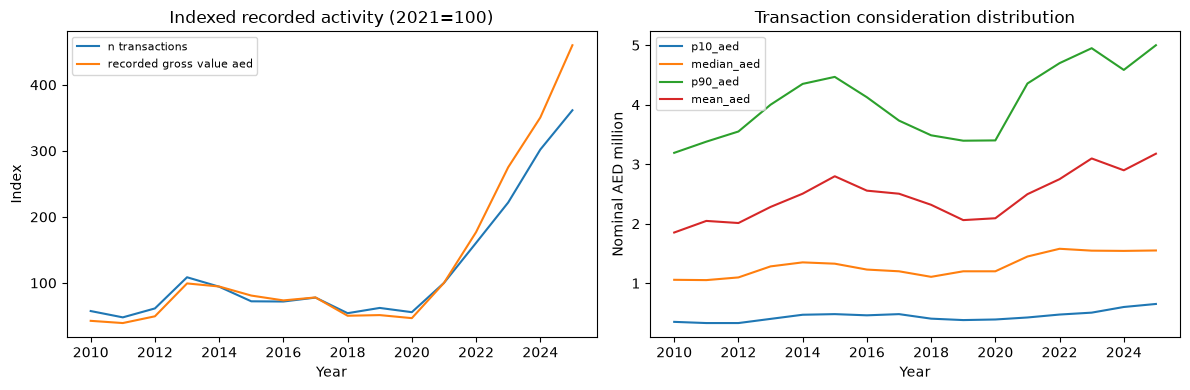

,metric,year_2021,year_2025,absolute_change,percent_change
0,n_transactions,5.942400e+04,2.148030e+05,1.553790e+05,261.48
1,recorded_gross_value_aed,1.483502e+11,6.823304e+11,5.339802e+11,359.95
2,mean_consideration_aed,2.496469e+06,3.176540e+06,6.800713e+05,27.24
3,median_consideration_aed,1.448431e+06,1.550000e+06,1.015690e+05,7.01
4,mean_median_ratio,1.720000e+00,2.050000e+00,3.300000e-01,18.90
5,consideration_p10_aed,4.237000e+05,6.508736e+05,2.271736e+05,53.62
6,consideration_p90_aed,4.356861e+06,5.000000e+06,6.431387e+05,14.76


In [4]:
# 07 — Growth, mean vs median, fixed nominal bands and quantile shifts
EPS=1e-12
market_yearly = market_yearly.sort_values('year').reset_index(drop=True)
for metric in ('n_transactions','recorded_gross_value_aed','mean_consideration_aed','median_consideration_aed'):
    market_yearly[f'{metric}_yoy_pct'] = market_yearly[metric].pct_change(fill_method=None)*100
endpoint_market = market_yearly.set_index('year').loc[[2021,2025]]
growth_comparison = pd.DataFrame([{'metric':name,'year_2021':endpoint_market.loc[2021,name],'year_2025':endpoint_market.loc[2025,name], 'absolute_change':endpoint_market.loc[2025,name]-endpoint_market.loc[2021,name], 'percent_change':100*(endpoint_market.loc[2025,name]/endpoint_market.loc[2021,name]-1) if endpoint_market.loc[2021,name] else np.nan} for name in ['n_transactions','recorded_gross_value_aed','mean_consideration_aed','median_consideration_aed','mean_median_ratio','consideration_p10_aed','consideration_p90_aed']])
PRICE_BINS=[0,500_000,1_000_000,1_500_000,2_000_000,5_000_000,10_000_000,float('inf')]
PRICE_LABELS=['<0.5M','0.5–1M','1–1.5M','1.5–2M','2–5M','5–10M','10M+']
p0['price_band']=pd.cut(p0.price_aed,PRICE_BINS,labels=PRICE_LABELS,include_lowest=True,right=False)
price_band_yearly=p0.groupby(['year','price_band'],observed=False).agg(n=('transaction_id','size'),gross_value_aed=('price_aed','sum')).reset_index()
price_band_yearly=price_band_yearly.merge(market_yearly[['year','n_transactions']],on='year')
price_band_yearly['count_share_pct']=100*price_band_yearly.n/price_band_yearly.n_transactions
assert price_band_yearly.groupby('year').n.sum().eq(market_yearly.set_index('year').n_transactions).all()
fig,axes=plt.subplots(1,2,figsize=(12,4))
for m in ('n_transactions','recorded_gross_value_aed'):
    v=market_yearly.set_index('year')[m]; axes[0].plot(v.index,100*v/v.loc[2021],label=m.replace('_',' '))
axes[0].set(title='Indexed recorded activity (2021=100)',ylabel='Index',xlabel='Year');axes[0].legend(fontsize=8)
for m in ('consideration_p10_aed','median_consideration_aed','consideration_p90_aed','mean_consideration_aed'):
    axes[1].plot(market_yearly.year,market_yearly[m]/1e6,label=m.replace('consideration_',''))
axes[1].set(title='Transaction consideration distribution',ylabel='Nominal AED million',xlabel='Year');axes[1].legend(fontsize=8)
plt.tight_layout();fig.savefig(FIG_OUT/'01_consideration_distribution.png',dpi=150,bbox_inches='tight'); plt.show()
display(growth_comparison.round(2))

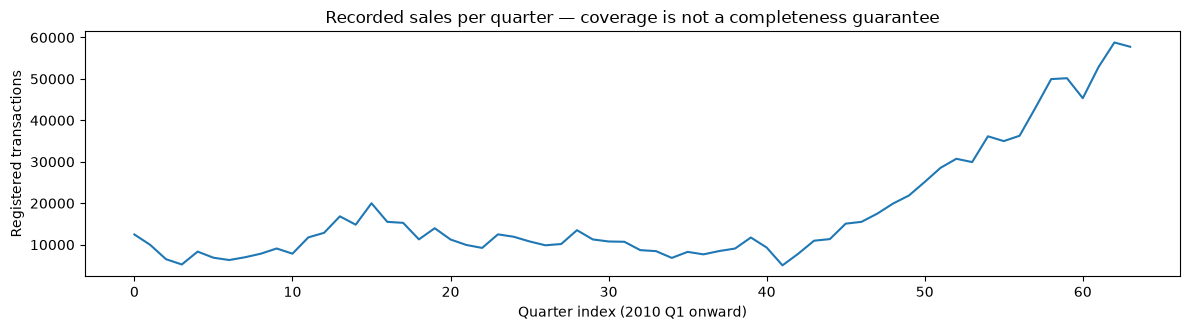

,year,quarter,year_quarter,n_transactions,active_areas,registration_classes,usage_classes,community_ids,low_count_relative_to_year_median
52,2023,1,2023-Q1,30726,136,2,3,136,False
53,2023,2,2023-Q2,29930,137,2,3,137,False
54,2023,3,2023-Q3,36152,134,2,3,134,False
55,2023,4,2023-Q4,34993,143,2,3,143,False
56,2024,1,2024-Q1,36279,141,2,3,141,False
57,2024,2,2024-Q2,43006,139,2,3,139,False
58,2024,3,2024-Q3,49961,141,2,3,141,False
59,2024,4,2024-Q4,50170,155,2,3,155,False
60,2025,1,2025-Q1,45353,147,2,3,147,False
61,2025,2,2025-Q2,52893,147,2,3,147,False


In [5]:
# 08 — Quarterly P0 aggregation, coverage and composition diagnostics
p0['quarter']=p0.quarter.astype(int)
market_quarterly=p0.groupby(['year','quarter'],observed=True).agg(n_transactions=('transaction_id','size'),recorded_gross_value_aed=('price_aed','sum'),median_consideration_aed=('price_aed','median'),active_areas=('area_id','nunique'),property_types=('property_type_label','nunique')).reset_index().sort_values(['year','quarter'])
market_quarterly['year_quarter']=market_quarterly.year.astype(str)+'-Q'+market_quarterly.quarter.astype(str)
for metric in ['n_transactions','recorded_gross_value_aed']:
    market_quarterly[f'{metric}_yoy_pct']=market_quarterly.groupby('quarter')[metric].pct_change(fill_method=None)*100
quarter_counts=market_quarterly.groupby('year').quarter.nunique()
assert quarter_counts.ge(1).all() and (market_quarterly.year.between(2010,2025)).all()
assert market_quarterly.n_transactions.sum()==len(p0)
assert np.isclose(market_quarterly.recorded_gross_value_aed.sum(),p0.price_aed.sum(),atol=.05)
category_breadth = p0.groupby(['year','quarter'],observed=True).agg(registration_classes=('reg_type_label','nunique'),usage_classes=('usage_label','nunique'),community_ids=('area_id','nunique')).reset_index()
historical_comparability=market_quarterly[['year','quarter','year_quarter','n_transactions','active_areas']].merge(category_breadth,on=['year','quarter'])
historical_comparability['low_count_relative_to_year_median']=historical_comparability.n_transactions.lt(historical_comparability.groupby('year').n_transactions.transform('median')*.25)
fig,ax=plt.subplots(figsize=(12,3.4)); ax.plot(np.arange(len(market_quarterly)),market_quarterly.n_transactions); ax.set(title='Recorded sales per quarter — coverage is not a completeness guarantee',ylabel='Registered transactions',xlabel='Quarter index (2010 Q1 onward)');plt.tight_layout();fig.savefig(FIG_OUT/'01_quarterly_activity.png',dpi=150,bbox_inches='tight');plt.show()
display(historical_comparability.tail(12))

## 02 · 09 — Interpretation protocol: activity is not demand or cash flow
Evaluate **both** count and registered-value changes; compare them with mean/median and quantile shifts. Highlight changes in transaction mix or geographic/category breadth coincident with large breaks. Seasonal quarterly patterns are descriptive, not evidence of demand shocks, and the source has no official universe coverage denominator. Dynamic numerical findings will be constructed in Cell 36 from validated calculations.

## 03 · 10 — Property mix, categories and growth attribution
**Population:** P0 for all property × usage groups; P1 Strict for residential area/price distributions. Categories must be exhaustive with an explicit Unknown label; source `Unit` is not synonymous with residential. Endpoint changes are **signed, additive accounting contributions**, not inferred economic causes. A rising count share and a rising value share are distinct results.

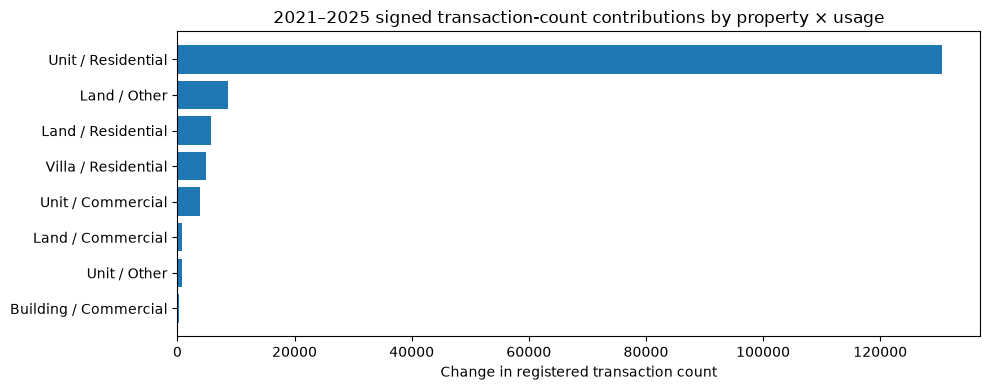

,property_group,usage_group,n_transactions_2021,n_transactions_2025,recorded_gross_value_aed_2021,recorded_gross_value_aed_2025,delta_n_transactions,delta_recorded_gross_value_aed
8,Unit,Residential,35984,166495,58732477966,321724035975,130511,262991558009
4,Land,Other,996,9703,8193296196,84519580878,8707,76326284682
5,Land,Residential,3240,8998,18897009250,68925298722,5758,50028289472
11,Villa,Residential,10957,15900,27938078864,71064083310,4943,43126004446
6,Unit,Commercial,2331,6110,2668077406,18013168052,3779,15345090646
3,Land,Commercial,1972,2826,11756949929,68759261655,854,57002311726
7,Unit,Other,2304,3038,5670321212,6803339573,734,1133018361
0,Building,Commercial,161,379,1900361234,12471242267,218,10570881033
2,Building,Residential,76,174,905726799,7253887559,98,6348160760
1,Building,Other,34,69,1058732163,5652076276,35,4593344113


In [6]:
# 11 — Property × usage annual composition and 2021–2025 signed growth bridges
for label,column in [('property','property_type_label'),('usage','usage_label')]:
    p0[label+'_group']=p0[column].astype('string').fillna('Unknown')
p0['property_usage_group']=p0['property_group']+' / '+p0['usage_group']
property_mix_yearly=p0.groupby(['year','property_group','usage_group'],observed=True).agg(n_transactions=('transaction_id','size'),recorded_gross_value_aed=('price_aed','sum')).reset_index()
property_mix_yearly=property_mix_yearly.merge(market_yearly[['year','n_transactions','recorded_gross_value_aed']].rename(columns={'n_transactions':'annual_n','recorded_gross_value_aed':'annual_value'}),on='year')
property_mix_yearly['count_share_pct']=100*property_mix_yearly.n_transactions/property_mix_yearly.annual_n
property_mix_yearly['value_share_pct']=100*property_mix_yearly.recorded_gross_value_aed/property_mix_yearly.annual_value.replace(0,np.nan)

def additive_growth(frame, keys, start=2021, end=2025, count='n_transactions', value='recorded_gross_value_aed'):
    if isinstance(keys,str): keys=[keys]
    pivot=frame.loc[frame.year.isin([start,end])].pivot_table(index=keys,columns='year',values=[count,value],aggfunc='sum',fill_value=0,observed=True)
    pivot.columns=[f'{metric}_{year}' for metric,year in pivot.columns]
    result=pivot.reset_index()
    for metric in [count,value]:
        for year in (start,end):
            col=f'{metric}_{year}'
            if col not in result: result[col]=0
        result[f'delta_{metric}']=result[f'{metric}_{end}']-result[f'{metric}_{start}']
    return result
property_growth_contributions=additive_growth(property_mix_yearly,['property_group','usage_group'])
assert property_growth_contributions.delta_n_transactions.sum()==int(endpoint_market.loc[2025,'n_transactions']-endpoint_market.loc[2021,'n_transactions'])
assert np.isclose(property_growth_contributions.delta_recorded_gross_value_aed.sum(),endpoint_market.loc[2025,'recorded_gross_value_aed']-endpoint_market.loc[2021,'recorded_gross_value_aed'],atol=.05)
top=property_growth_contributions.nlargest(8,'delta_n_transactions')
fig,ax=plt.subplots(figsize=(10,4)); ax.barh((top.property_group+' / '+top.usage_group)[::-1],top.delta_n_transactions[::-1]); ax.set(title='2021–2025 signed transaction-count contributions by property × usage',xlabel='Change in registered transaction count');plt.tight_layout();fig.savefig(FIG_OUT/'01_property_growth_contributions.png',dpi=150,bbox_inches='tight');plt.show()
display(property_growth_contributions.sort_values('delta_n_transactions',ascending=False))

In [7]:
# 12 — Historical broad-market vs quality-filtered residential cohorts
rows=[]
for name,frame in [('P0',p0),('P1_CORE',core),('P1_STRICT',p1)]:
    t=frame.groupby('year',observed=True).agg(n_transactions=('transaction_id','size'),recorded_gross_value_aed=('price_aed','sum'),mean_consideration_aed=('price_aed','mean'),median_consideration_aed=('price_aed','median')).reset_index()
    t['population']=name;rows.append(t)
market_cohort_yearly=pd.concat(rows,ignore_index=True)
w=market_cohort_yearly.pivot(index='year',columns='population',values='n_transactions')
assert ((w['P1_STRICT']<=w['P1_CORE']) & (w['P1_CORE']<=w['P0'])).all()
residential_coverage=market_cohort_yearly.pivot(index='year',columns='population',values='n_transactions').reset_index()
residential_coverage['core_share_P0_pct']=100*residential_coverage.P1_CORE/residential_coverage.P0
residential_coverage['strict_retention_of_core_pct']=100*residential_coverage.P1_STRICT/residential_coverage.P1_CORE
display(residential_coverage.round(2))

population,year,P0,P1_CORE,P1_STRICT,core_share_P0_pct,strict_retention_of_core_pct
0,2010,34120,28231,27717,82.74,98.18
1,2011,28439,22335,21945,78.54,98.25
2,2012,36479,26643,26113,73.04,98.01
3,2013,64517,48253,47400,74.79,98.23
4,2014,56018,42002,41323,74.98,98.38
5,2015,42882,32082,31581,74.81,98.44
6,2016,42692,31205,30762,73.09,98.58
7,2017,46230,35675,35267,77.17,98.86
8,2018,32194,25082,24814,77.91,98.93
9,2019,36925,30950,30661,83.82,99.07


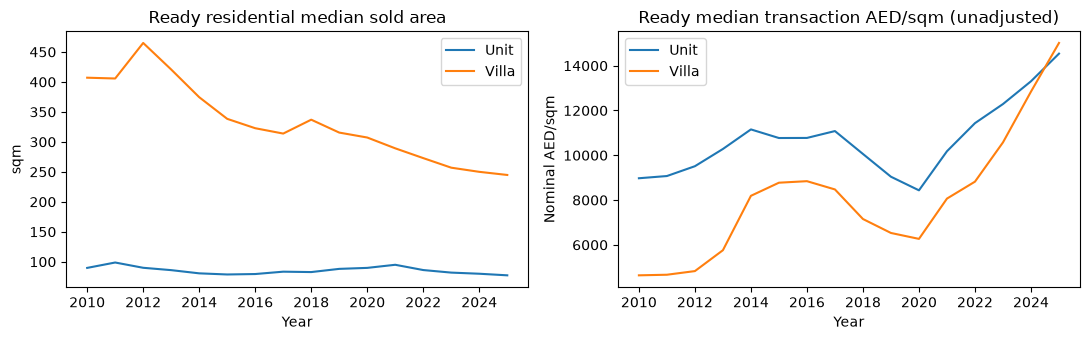

,year,n,median_area_sqm,mean_area_sqm,median_consideration_aed,mean_consideration_aed,median_aed_per_sqm
11,2021,46302,109.58,148.932679,1316824.0,1.778190e+06,11037.735849
12,2022,73415,92.21,130.594432,1422583.0,1.950101e+06,13955.342903
13,2023,106643,82.73,119.780040,1420000.0,2.004905e+06,15261.251940
14,2024,152600,79.32,111.172251,1404746.5,1.947063e+06,16747.751732
15,2025,178962,76.22,102.502924,1380000.0,1.999992e+06,18149.523543


In [8]:
# 13 — P1 Strict residential transaction-price, area and AED/sqm distribution shifts
residential_rows=[]
for (year,typ,reg),g in p1.groupby(['year','property_type_label','reg_type_label'],dropna=False,observed=True):
    item={'year':int(year),'property_type':str(typ),'registration':str(reg),'n':len(g),'recorded_value_aed':g.price_aed.sum(),'mean_price_aed':g.price_aed.mean(),'median_price_aed':g.price_aed.median(),'median_area_sqm':g.area_sqm.median(),'median_aed_per_sqm':g.price_per_sqm.median()}
    for field,label in [('price_aed','consideration'),('area_sqm','area'),('price_per_sqm','aed_per_sqm')]:
        for q in (.1,.25,.75,.9):item[f'{label}_p{int(q*100):02d}']=g[field].quantile(q)
    residential_rows.append(item)
residential_distribution_yearly=pd.DataFrame(residential_rows)
residential_yearly=p1.groupby('year',observed=True).agg(n=('transaction_id','size'),median_area_sqm=('area_sqm','median'),mean_area_sqm=('area_sqm','mean'),median_consideration_aed=('price_aed','median'),mean_consideration_aed=('price_aed','mean'),median_aed_per_sqm=('price_per_sqm','median')).reset_index()
assert residential_distribution_yearly.groupby('year').n.sum().eq(residential_yearly.set_index('year').n).all()
residential_distribution_shift=additive_growth(residential_distribution_yearly.rename(columns={'n':'n_transactions','recorded_value_aed':'recorded_gross_value_aed'}),['property_type','registration'])
fig,ax=plt.subplots(1,2,figsize=(11,3.5))
for typ in ('Unit','Villa'):
    d=residential_distribution_yearly.loc[(residential_distribution_yearly.property_type==typ)&(residential_distribution_yearly.registration=='Ready')]
    ax[0].plot(d.year,d.median_area_sqm,label=typ);ax[1].plot(d.year,d.median_aed_per_sqm,label=typ)
ax[0].set(title='Ready residential median sold area',ylabel='sqm',xlabel='Year');ax[1].set(title='Ready median transaction AED/sqm (unadjusted)',ylabel='Nominal AED/sqm',xlabel='Year');ax[0].legend();ax[1].legend();plt.tight_layout();fig.savefig(FIG_OUT/'01_residential_area_price_distribution.png',dpi=150,bbox_inches='tight');plt.show()
display(residential_yearly.tail())

## 03 · 14 — Property-composition interpretation
Report contributions from property × usage cells separately from the residential transaction-level price and area distribution. A rising overall mean or median can reflect changing sold-property composition. Mean/median divergence and changes in upper and lower quantiles identify **distributional differences**, not within-property appreciation. No claims about housing-stock inventory or builders reducing floorplans follow from this transaction sample. Final quantitative statements are generated in Cell 36.

## 04 · 15 — Registration classification and value semantics
**Source field:** `reg_type_label` (`Ready`, `Off-Plan`, and explicit Unknown). Ready does not establish a secondary-market resale; Off-Plan registration value does **not** represent developer receipts or same-year cash transfer. Compare both **count** and **recorded-value** shares, and inspect registration within property × usage groups before interpreting the aggregate mix.

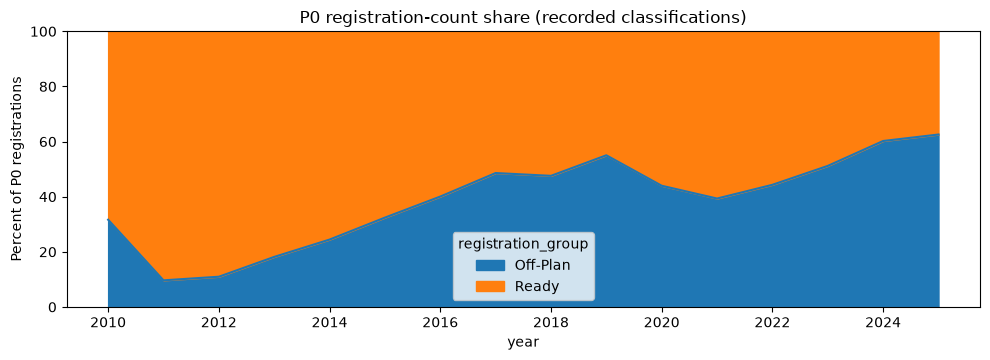

,year,registration_group,n_transactions,recorded_gross_value_aed,mean_consideration_aed,median_consideration_aed,year_n,year_value,count_share_pct,value_share_pct,population
22,2021,Off-Plan,23375,43988359513,1881854.95,1355888.0,59424,148350178469,39.34,29.65,P0
23,2021,Ready,36049,104361818956,2894999.00,1550000.0,59424,148350178469,60.66,70.35,P0
30,2025,Off-Plan,134384,292738825292,2178375.59,1431778.5,214803,682330410397,62.56,42.90,P0
31,2025,Ready,80419,389591585105,4844521.63,1954260.0,214803,682330410397,37.44,57.10,P0


In [9]:
# 16 — Registration year × population shares and full reconciliation
p0['registration_group']=p0.reg_type_label.astype('string').fillna('Unknown')
p1['registration_group']=p1.reg_type_label.astype('string').fillna('Unknown')
reg_tables=[]
for pop,frame in [('P0',p0),('P1_STRICT',p1)]:
    t=frame.groupby(['year','registration_group'],observed=True).agg(n_transactions=('transaction_id','size'),recorded_gross_value_aed=('price_aed','sum'),mean_consideration_aed=('price_aed','mean'),median_consideration_aed=('price_aed','median')).reset_index()
    den=frame.groupby('year').agg(year_n=('transaction_id','size'),year_value=('price_aed','sum')).reset_index()
    t=t.merge(den,on='year'); t['count_share_pct']=100*t.n_transactions/t.year_n; t['value_share_pct']=100*t.recorded_gross_value_aed/t.year_value.replace(0,np.nan); t['population']=pop;reg_tables.append(t)
registration_mix_yearly=pd.concat(reg_tables,ignore_index=True)
for pop,grp in registration_mix_yearly.groupby('population'):
    original=p0 if pop=='P0' else p1
    assert grp.n_transactions.sum()==len(original)
    assert np.isclose(grp.recorded_gross_value_aed.sum(),original.price_aed.sum(),atol=.05)
reg_plt=registration_mix_yearly.query("population=='P0'").pivot(index='year',columns='registration_group',values='count_share_pct').fillna(0)
regax=reg_plt.plot.area(figsize=(10,3.7),title='P0 registration-count share (recorded classifications)',ylabel='Percent of P0 registrations',ylim=(0,100));plt.tight_layout();regax.figure.savefig(FIG_OUT/'01_registration_mix.png',dpi=150,bbox_inches='tight');plt.show()
display(registration_mix_yearly.loc[(registration_mix_yearly.population=='P0') & registration_mix_yearly.year.isin([2021,2025])].round(2))

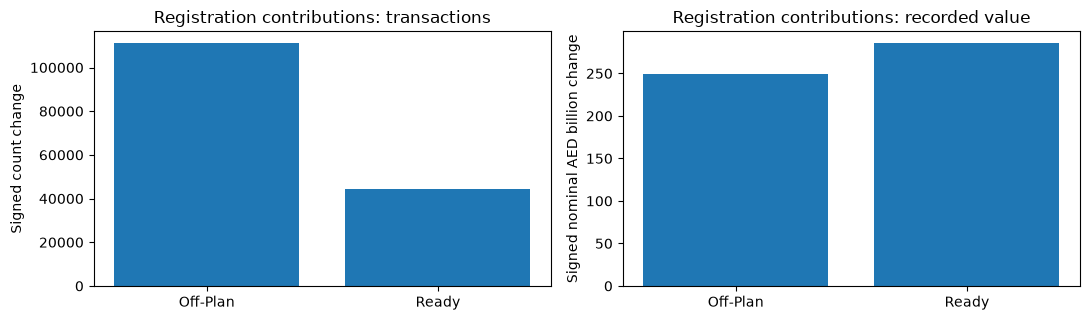

,registration_group,n_transactions_2021,n_transactions_2025,recorded_gross_value_aed_2021,recorded_gross_value_aed_2025,delta_n_transactions,delta_recorded_gross_value_aed
0,Off-Plan,23375,134384,43988359513,292738825292,111009,248750465779
1,Ready,36049,80419,104361818956,389591585105,44370,285229766149


In [10]:
# 17 — Signed Ready / Off-Plan / Unknown count and value contributions
registration_growth_contributions=additive_growth(registration_mix_yearly.query("population=='P0'"),['registration_group'])
expected_delta_n=int(endpoint_market.loc[2025,'n_transactions']-endpoint_market.loc[2021,'n_transactions'])
expected_delta_v=float(endpoint_market.loc[2025,'recorded_gross_value_aed']-endpoint_market.loc[2021,'recorded_gross_value_aed'])
assert registration_growth_contributions.delta_n_transactions.sum()==expected_delta_n
assert np.isclose(registration_growth_contributions.delta_recorded_gross_value_aed.sum(),expected_delta_v,atol=.05)
fig,axes=plt.subplots(1,2,figsize=(11,3.3))
axes[0].bar(registration_growth_contributions.registration_group,registration_growth_contributions.delta_n_transactions);axes[0].set(title='Registration contributions: transactions',ylabel='Signed count change')
axes[1].bar(registration_growth_contributions.registration_group,registration_growth_contributions.delta_recorded_gross_value_aed/1e9);axes[1].set(title='Registration contributions: recorded value',ylabel='Signed nominal AED billion change')
plt.tight_layout();fig.savefig(FIG_OUT/'01_registration_growth_bridge.png',dpi=150,bbox_inches='tight');plt.show()
display(registration_growth_contributions)

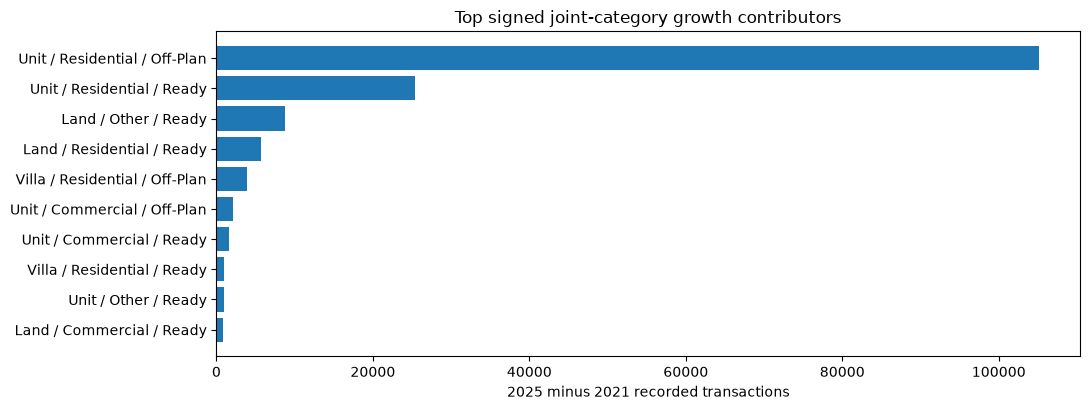

,property_group,usage_group,registration_group,n_transactions_2021,n_transactions_2025,recorded_gross_value_aed_2021,recorded_gross_value_aed_2025,delta_n_transactions,delta_recorded_gross_value_aed
10,Unit,Residential,Off-Plan,16680,121808,31210449454,245684070336,105128,214473620882
11,Unit,Residential,Ready,19304,44687,27522028512,76039965639,25383,48517937127
4,Land,Other,Ready,996,9703,8193296196,84519580878,8707,76326284682
5,Land,Residential,Ready,3240,8998,18897009250,68925298722,5758,50028289472
14,Villa,Residential,Off-Plan,5345,9294,9884325411,37682399980,3949,27798074569
6,Unit,Commercial,Off-Plan,67,2187,151713040,7703032660,2120,7551319620
7,Unit,Commercial,Ready,2264,3923,2516364366,10310135392,1659,7793771026
15,Villa,Residential,Ready,5612,6606,18053753453,33381683330,994,15327929877
9,Unit,Other,Ready,1021,1943,2928449604,5134017257,922,2205567653
3,Land,Commercial,Ready,1972,2826,11756949929,68759261655,854,57002311726


In [11]:
# 18 — Joint property × usage × registration contributions; within-type mix
joint_keys=['property_group','usage_group','registration_group']
property_registration_yearly=p0.groupby(['year']+joint_keys,observed=True).agg(n_transactions=('transaction_id','size'),recorded_gross_value_aed=('price_aed','sum')).reset_index()
property_registration_growth=additive_growth(property_registration_yearly,joint_keys)
assert property_registration_growth.delta_n_transactions.sum()==expected_delta_n
assert np.isclose(property_registration_growth.delta_recorded_gross_value_aed.sum(),expected_delta_v,atol=.05)
within_category_reg=property_registration_yearly.copy()
within_category_reg['within_type_count_share_pct']=100*within_category_reg.n_transactions/within_category_reg.groupby(['year','property_group','usage_group']).n_transactions.transform('sum')
within_category_reg['within_type_value_share_pct']=100*within_category_reg.recorded_gross_value_aed/within_category_reg.groupby(['year','property_group','usage_group']).recorded_gross_value_aed.transform('sum').replace(0,np.nan)
top_joint=property_registration_growth.nlargest(10,'delta_n_transactions')
fig,ax=plt.subplots(figsize=(11,4.2));labels=top_joint.property_group+' / '+top_joint.usage_group+' / '+top_joint.registration_group; ax.barh(labels[::-1],top_joint.delta_n_transactions[::-1]);ax.set(title='Top signed joint-category growth contributors',xlabel='2025 minus 2021 recorded transactions');plt.tight_layout();fig.savefig(FIG_OUT/'01_joint_growth_contributions.png',dpi=150,bbox_inches='tight');plt.show()
display(property_registration_growth.sort_values('delta_n_transactions',ascending=False).head(15))

## 04 · 19 — RQ05 interpretation boundary
Use absolute category changes first, because percentage *contributions* can be negative or exceed 100% if category movements offset one another. The joint property × usage × registration bridge tests whether an aggregate Off-Plan share change partly reflects a changing category mix. It does **not** establish speculative behavior, financing mechanisms or payment timing.

## 05 · 20 — Geography, concentration and contribution contract
Use `area_id` rather than area names to group communities; keep unknown geography explicit for additive count/value reconciliation. Concentration HHI uses the **known-geography universe** and separately reports its coverage. An absent 2021/2025 registration is not evidence that the community did not physically exist. Counts are not measures of liquidity relative to the housing stock. A common-area universe supports sensitivity analysis, not a complete balanced property panel.

In [12]:
# 21 — P0 community-year panel, known-geography coverage and unknown bucket
p0['area_key']=p0.area_id.astype('string').fillna('__UNKNOWN__')
community_yearly=p0.groupby(['year','area_key'],observed=True).agg(n_transactions=('transaction_id','size'),recorded_gross_value_aed=('price_aed','sum')).reset_index()
community_yearly['is_known_area']=community_yearly.area_key.ne('__UNKNOWN__')
area_coverage=community_yearly.groupby('year',observed=True).apply(lambda g:pd.Series({'known_n':g.loc[g.is_known_area,'n_transactions'].sum(),'unknown_n':g.loc[~g.is_known_area,'n_transactions'].sum(),'known_value_aed':g.loc[g.is_known_area,'recorded_gross_value_aed'].sum(),'unknown_value_aed':g.loc[~g.is_known_area,'recorded_gross_value_aed'].sum(),'active_known_areas':g.is_known_area.sum()}),include_groups=False).reset_index()
area_coverage=area_coverage.merge(market_yearly[['year','n_transactions','recorded_gross_value_aed']],on='year')
area_coverage['known_count_coverage_pct']=100*area_coverage.known_n/area_coverage.n_transactions
area_coverage['known_value_coverage_pct']=100*area_coverage.known_value_aed/area_coverage.recorded_gross_value_aed.replace(0,np.nan)
assert (area_coverage.known_n+area_coverage.unknown_n==area_coverage.n_transactions).all()
assert np.allclose(area_coverage.known_value_aed+area_coverage.unknown_value_aed,area_coverage.recorded_gross_value_aed,rtol=1e-12,atol=.05)
area_share_yearly=community_yearly.merge(area_coverage[['year','known_n','known_value_aed']],on='year')
area_share_yearly['known_area_count_share']=np.where(area_share_yearly.is_known_area,area_share_yearly.n_transactions/area_share_yearly.known_n.replace(0,np.nan),np.nan)
area_share_yearly['known_area_value_share']=np.where(area_share_yearly.is_known_area,area_share_yearly.recorded_gross_value_aed/area_share_yearly.known_value_aed.replace(0,np.nan),np.nan)
display(area_coverage.tail())

,year,known_n,unknown_n,known_value_aed,unknown_value_aed,active_known_areas,n_transactions,recorded_gross_value_aed,known_count_coverage_pct,known_value_coverage_pct
11,2021,59424,0,148350178469,0,155,59424,148350178469,100.0,100.0
12,2022,95471,0,262437530423,0,170,95471,262437530423,100.0,100.0
13,2023,131801,0,408152113488,0,167,131801,408152113488,100.0,100.0
14,2024,179416,0,519915960524,0,176,179416,519915960524,100.0,100.0
15,2025,214803,0,682330410397,0,169,214803,682330410397,100.0,100.0


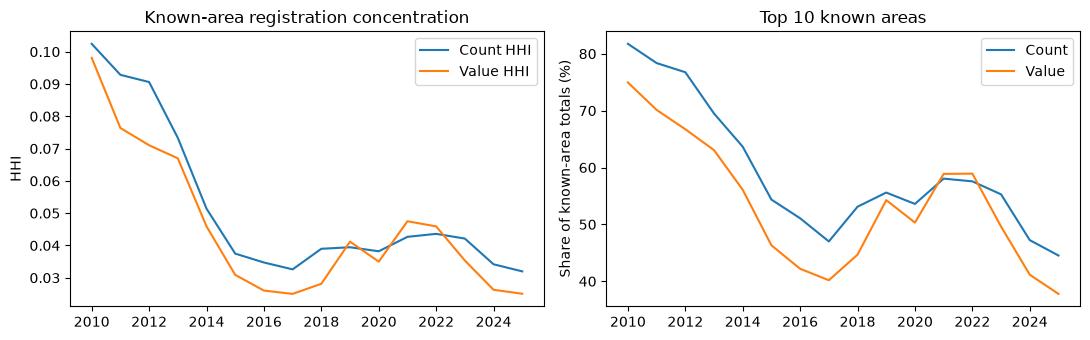

,year,active_known_areas,count_hhi,value_hhi,effective_count_communities,top5_count_share_pct,top10_count_share_pct,top10_value_share_pct,known_count_coverage_pct,known_value_coverage_pct
11,2021,155.0,0.042678,0.047509,23.431499,35.850835,58.045571,58.876285,100.0,100.0
12,2022,170.0,0.043605,0.045907,22.933259,35.873721,57.567219,58.924066,100.0,100.0
13,2023,167.0,0.042142,0.035353,23.729431,36.180302,55.285620,49.615911,100.0,100.0
14,2024,176.0,0.034184,0.026288,29.253182,29.262719,47.236032,41.154443,100.0,100.0
15,2025,169.0,0.031983,0.025058,31.266434,28.497274,44.530570,37.786596,100.0,100.0


In [13]:
# 22 — Count/value HHI, effective community count and concentration
def concentration_metrics(g):
    g=g.loc[g.is_known_area]
    if g.empty:return pd.Series({'active_known_areas':0,'count_hhi':np.nan,'value_hhi':np.nan,'effective_count_communities':np.nan,'top5_count_share_pct':np.nan,'top10_count_share_pct':np.nan,'top10_value_share_pct':np.nan})
    s=g.n_transactions/g.n_transactions.sum();v=g.recorded_gross_value_aed/g.recorded_gross_value_aed.sum() if g.recorded_gross_value_aed.sum() else pd.Series(0.,index=g.index)
    hhi=float((s*s).sum())
    return pd.Series({'active_known_areas':len(g),'count_hhi':hhi,'value_hhi':float((v*v).sum()),'effective_count_communities':1/hhi if hhi else np.nan,'top5_count_share_pct':100*s.nlargest(5).sum(),'top10_count_share_pct':100*s.nlargest(10).sum(),'top10_value_share_pct':100*v.nlargest(10).sum()})
community_concentration_yearly=community_yearly.groupby('year').apply(concentration_metrics,include_groups=False).reset_index()
community_concentration_yearly=community_concentration_yearly.merge(area_coverage[['year','known_count_coverage_pct','known_value_coverage_pct']],on='year')
assert community_concentration_yearly.count_hhi.between(0,1).all()
assert community_concentration_yearly.value_hhi.between(0,1).all()
fig,axes=plt.subplots(1,2,figsize=(11,3.5))
axes[0].plot(community_concentration_yearly.year,community_concentration_yearly.count_hhi,label='Count HHI');axes[0].plot(community_concentration_yearly.year,community_concentration_yearly.value_hhi,label='Value HHI');axes[0].legend();axes[0].set(title='Known-area registration concentration',ylabel='HHI')
axes[1].plot(community_concentration_yearly.year,community_concentration_yearly.top10_count_share_pct,label='Count');axes[1].plot(community_concentration_yearly.year,community_concentration_yearly.top10_value_share_pct,label='Value');axes[1].legend();axes[1].set(title='Top 10 known areas',ylabel='Share of known-area totals (%)');plt.tight_layout();fig.savefig(FIG_OUT/'01_community_concentration.png',dpi=150,bbox_inches='tight');plt.show()
display(community_concentration_yearly.tail())

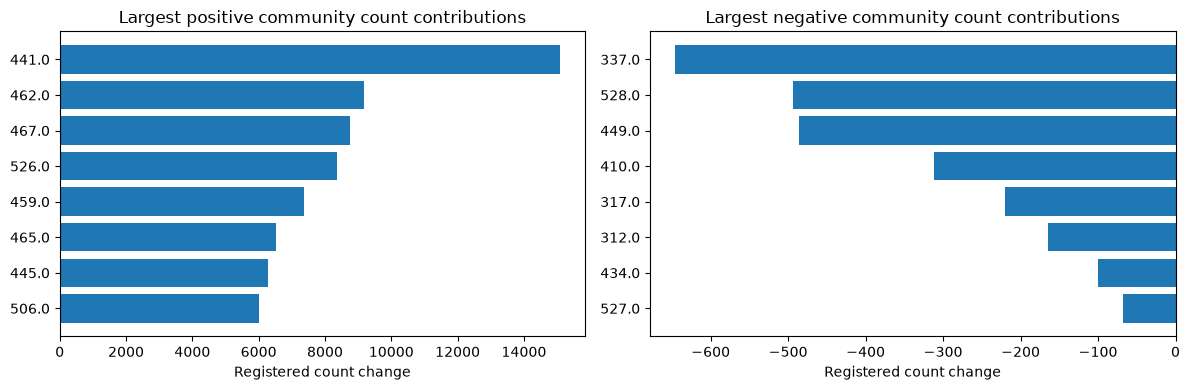

,endpoint_status,areas,delta_n,delta_value_aed
0,both_endpoints,147,149488,480151140827
1,only_2021,8,-988,-1270077077
2,only_2025,22,6879,55099168178


,year,common_areas,count_share_all_P0_pct,value_share_all_P0_pct,known_areas_n
0,2021,147,98.337372,99.143865,155
1,2025,147,96.797531,91.924855,169


,year,active_known_areas,count_hhi,value_hhi,effective_count_communities,top5_count_share_pct,top10_count_share_pct,top10_value_share_pct
0,2021,147.0,0.043992,0.048301,22.731257,36.456979,59.026970,59.384697
1,2025,147.0,0.033605,0.027403,29.757545,29.440084,46.003828,41.105962


In [14]:
# 23 — 2021/2025 community contributors, entry/exit and balanced geography
community_growth_contributions=additive_growth(community_yearly,['area_key'])
community_growth_contributions['endpoint_status']=np.select([community_growth_contributions.n_transactions_2021.gt(0)&community_growth_contributions.n_transactions_2025.gt(0),community_growth_contributions.n_transactions_2021.eq(0),community_growth_contributions.n_transactions_2025.eq(0)],['both_endpoints','only_2025','only_2021'],default='unclassified')
community_growth_contributions.loc[community_growth_contributions.area_key.eq('__UNKNOWN__'),'endpoint_status']='unknown_geography'
assert community_growth_contributions.delta_n_transactions.sum()==expected_delta_n
assert np.isclose(community_growth_contributions.delta_recorded_gross_value_aed.sum(),expected_delta_v,atol=.05)
community_growth_by_status=community_growth_contributions.groupby('endpoint_status').agg(areas=('area_key','size'),delta_n=('delta_n_transactions','sum'),delta_value_aed=('delta_recorded_gross_value_aed','sum')).reset_index()
common_areas=set(community_growth_contributions.loc[(community_growth_contributions.endpoint_status=='both_endpoints'),'area_key'])
common_coverage=[]; balanced_concentration=[]
for y in (2021,2025):
    yall=community_yearly.loc[community_yearly.year.eq(y)]
    common=yall[yall.area_key.isin(common_areas)]
    known=yall[yall.is_known_area]
    common_coverage.append({'year':y,'common_areas':len(common_areas),'count_share_all_P0_pct':100*common.n_transactions.sum()/yall.n_transactions.sum(),'value_share_all_P0_pct':100*common.recorded_gross_value_aed.sum()/yall.recorded_gross_value_aed.sum(),'known_areas_n':len(known)})
    balanced_concentration.append({'year':y,**concentration_metrics(common).to_dict()})
common_area_coverage=pd.DataFrame(common_coverage)
balanced_community_concentration=pd.DataFrame(balanced_concentration)
# Ranked positive and negative contributors; names remain optional display labels only.
large=community_growth_contributions.loc[community_growth_contributions.area_key.ne('__UNKNOWN__')].copy()
fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,g,title in [(axes[0],large.nlargest(8,'delta_n_transactions'),'Largest positive'),(axes[1],large.nsmallest(8,'delta_n_transactions'),'Largest negative')]:
    ax.barh(g.area_key.astype(str).iloc[::-1],g.delta_n_transactions.iloc[::-1]);ax.set(title=title+' community count contributions',xlabel='Registered count change')
plt.tight_layout();fig.savefig(FIG_OUT/'01_community_growth_contributions.png',dpi=150,bbox_inches='tight');plt.show()
display(community_growth_by_status);display(common_area_coverage);display(balanced_community_concentration)

## 05 · 24 — Geographic interpretation policy
Compare community contribution rankings with HHI/top-10 trends and fixed-common-community coverage. Positive changes in only-2025 communities reflect first *observed endpoint activity*, not verified new construction or population inflows. Value concentration can rise while count concentration falls. Claims are appropriately qualified whenever unknown-area shares or balanced-universe coverage are material.

## 06 · 25 — Nominal budgets and residential upper tails
**Population:** P1 Strict. AED 1M/1.5M/2M are fixed *nominal registered price* thresholds, not household income affordability, mortgage eligibility, active listings or inflation-adjusted purchasing power. Top-decile/top-percentile value shares describe **transaction** distribution, not buyer wealth. Exact rank-based top-k with stable transaction-ID tie breaking makes top-tail membership reproducible. 2026 excluded.

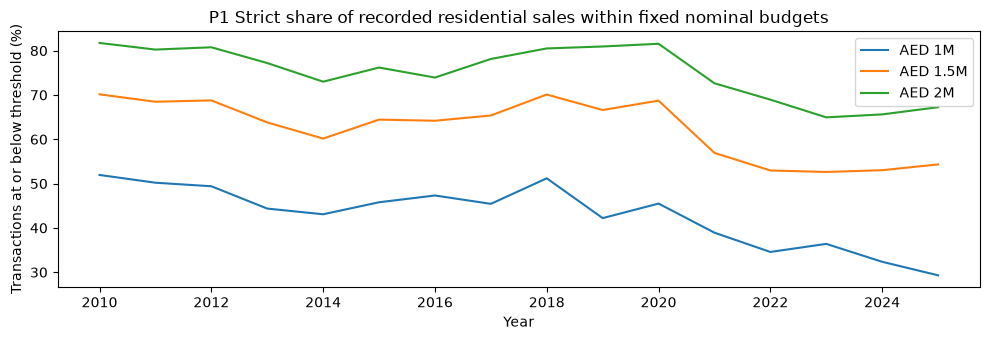

,year,property_type,budget_aed,eligible_n,within_budget_n,within_budget_pct,cohort,currency
66,2021,Unit,1000000,35546,17645,49.64,P1_STRICT,nominal_AED
67,2021,Unit,1500000,35546,23448,65.97,P1_STRICT,nominal_AED
68,2021,Unit,2000000,35546,27669,77.84,P1_STRICT,nominal_AED
69,2021,Villa,1000000,10756,378,3.51,P1_STRICT,nominal_AED
70,2021,Villa,1500000,10756,2910,27.05,P1_STRICT,nominal_AED
71,2021,Villa,2000000,10756,5963,55.44,P1_STRICT,nominal_AED
90,2025,Unit,1000000,163322,51997,31.84,P1_STRICT,nominal_AED
91,2025,Unit,1500000,163322,96207,58.91,P1_STRICT,nominal_AED
92,2025,Unit,2000000,163322,118768,72.72,P1_STRICT,nominal_AED
93,2025,Villa,1000000,15640,442,2.83,P1_STRICT,nominal_AED


In [15]:
# 26 — Fixed-budget eligibility count/denominator and trend
BUDGETS=(1_000_000,1_500_000,2_000_000)
budget_rows=[]
for (year,typ),g in p1.groupby(['year','property_type_label'],observed=True):
    for budget in BUDGETS:
        n=int(g.price_aed.le(budget).sum())
        budget_rows.append({'year':int(year),'property_type':str(typ),'budget_aed':budget,'eligible_n':len(g),'within_budget_n':n,'within_budget_pct':100*n/len(g),'cohort':'P1_STRICT','currency':'nominal_AED'})
budget_accessibility=pd.DataFrame(budget_rows)
assert budget_accessibility.groupby(['year','property_type']).apply(lambda x:x.sort_values('budget_aed').within_budget_n.is_monotonic_increasing,include_groups=False).all()
fig,ax=plt.subplots(figsize=(10,3.5))
for budget in BUDGETS:
    t=p1.groupby('year').price_aed.apply(lambda x:100*x.le(budget).mean())
    ax.plot(t.index,t.values,label=f'AED {budget/1e6:g}M')
ax.set(title='P1 Strict share of recorded residential sales within fixed nominal budgets',ylabel='Transactions at or below threshold (%)',xlabel='Year');ax.legend();plt.tight_layout();fig.savefig(FIG_OUT/'01_budget_thresholds.png',dpi=150,bbox_inches='tight');plt.show()
display(budget_accessibility.query('year in [2021,2025]').round(2))

In [16]:
# 27 — Within-budget property, registration, size and bedroom completeness
budget_segment_rows=[]
for year in (2021,2025):
    for budget in BUDGETS:
        selected=p1.loc[p1.year.eq(year)&p1.price_aed.le(budget)]
        for typ,g in selected.groupby('property_type_label',observed=True):
            budget_segment_rows.append({'year':year,'budget_aed':budget,'property_type':typ,'within_budget_n':len(g),'median_area_sqm':g.area_sqm.median(),'area_p25_sqm':g.area_sqm.quantile(.25),'area_p75_sqm':g.area_sqm.quantile(.75),'bedroom_known_n':g.bedroom_label.notna().sum(),'bedroom_known_pct':100*g.bedroom_label.notna().mean(),'ready_share_pct':100*g.reg_type_label.eq('Ready').mean(),'median_consideration_aed':g.price_aed.median()})
budget_segment_composition=pd.DataFrame(budget_segment_rows)
assert budget_segment_composition.bedroom_known_pct.between(0,100).all()
display(budget_segment_composition.round(2))

,year,budget_aed,property_type,within_budget_n,median_area_sqm,area_p25_sqm,area_p75_sqm,bedroom_known_n,bedroom_known_pct,ready_share_pct,median_consideration_aed
0,2021,1000000,Unit,17645,62.94,41.61,79.23,17634,99.94,56.66,580000.0
1,2021,1000000,Villa,378,123.47,98.98,137.76,221,58.47,46.30,820000.0
2,2021,1500000,Unit,23448,69.41,45.26,89.34,23436,99.95,56.28,702000.0
3,2021,1500000,Villa,2910,161.00,135.20,174.80,2404,82.61,32.13,1300000.0
4,2021,2000000,Unit,27669,73.46,49.09,101.65,27653,99.94,56.28,792406.0
5,2021,2000000,Villa,5963,174.00,140.43,207.56,5252,88.08,31.39,1521888.0
6,2025,1000000,Unit,51997,41.74,36.81,62.48,51997,100.00,39.07,713137.0
7,2025,1000000,Villa,442,87.99,52.88,89.95,378,85.52,43.44,898668.0
8,2025,1500000,Unit,96207,59.66,39.68,74.72,96203,100.00,30.09,959000.0
9,2025,1500000,Villa,1023,88.00,81.14,90.75,902,88.17,31.57,1070000.0


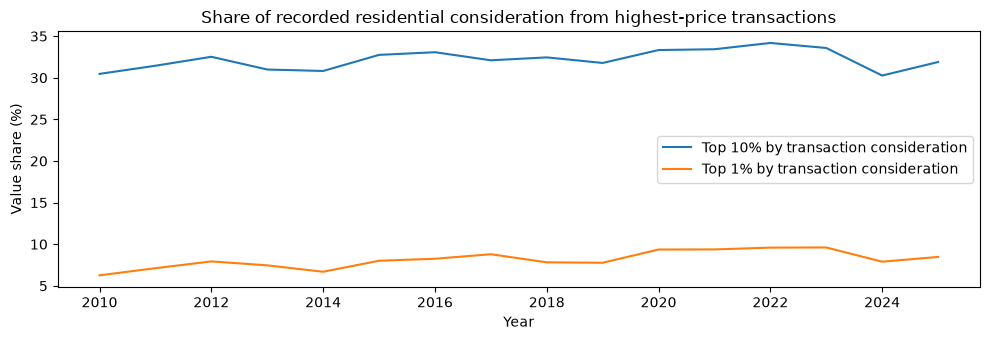

,year,property_type,tail_fraction,eligible_n,total_value_aed,tail_n,tail_total_value_aed,tail_value_share_pct,cutoff_price_aed
86,2021,ALL_RESIDENTIAL,0.10,46302,8.233377e+10,4631,2.752281e+10,33.428336,3384888.0
87,2021,ALL_RESIDENTIAL,0.01,46302,8.233377e+10,464,7.718576e+09,9.374739,9750000.0
94,2025,ALL_RESIDENTIAL,0.10,178962,3.579226e+11,17897,1.141446e+11,31.890872,3814000.0
95,2025,ALL_RESIDENTIAL,0.01,178962,3.579226e+11,1790,3.031530e+10,8.469793,9588000.0


In [17]:
# 28 — Exact top-k upper transaction-value tails and within-property sensitivity
def top_tail(frame,portion):
    ordered=frame.sort_values(['price_aed','transaction_id'],ascending=[False,True],kind='mergesort')
    k=max(1,math.ceil(len(ordered)*portion))
    subset=ordered.iloc[:k]
    value=frame.price_aed.sum()
    return {'tail_n':k,'tail_total_value_aed':float(subset.price_aed.sum()),'tail_value_share_pct':100*subset.price_aed.sum()/value if value else np.nan,'cutoff_price_aed':float(subset.price_aed.iloc[-1])}
tail_rows=[]
for (year,typ),g in p1.groupby(['year','property_type_label'],observed=True):
    for q in (.10,.01):tail_rows.append({'year':int(year),'property_type':str(typ),'tail_fraction':q,'eligible_n':len(g),'total_value_aed':float(g.price_aed.sum()),**top_tail(g,q)})
    # Keep fixed-price cutoffs independent of top-percentile cutoffs.
price_tail_concentration=pd.DataFrame(tail_rows)
tail_overall=[]
for year,g in p1.groupby('year'):
    for q in (.10,.01):tail_overall.append({'year':int(year),'property_type':'ALL_RESIDENTIAL','tail_fraction':q,'eligible_n':len(g),'total_value_aed':float(g.price_aed.sum()),**top_tail(g,q)})
price_tail_concentration=pd.concat([price_tail_concentration,pd.DataFrame(tail_overall)],ignore_index=True)
fixed_tail_rows=[]
for (year,typ),g in p1.groupby(['year','property_type_label'],observed=True):
    for threshold in (2_000_000,5_000_000,10_000_000):
        selected=g.price_aed.ge(threshold)
        fixed_tail_rows.append({'year':int(year),'property_type':str(typ),'threshold_aed':threshold,'eligible_n':len(g),'over_threshold_n':int(selected.sum()),'over_threshold_value_share_pct':100*g.loc[selected,'price_aed'].sum()/g.price_aed.sum()})
fixed_price_tail=pd.DataFrame(fixed_tail_rows)
assert price_tail_concentration.tail_value_share_pct.between(0,100.00001).all()
fig,ax=plt.subplots(figsize=(10,3.5))
for q in (.10,.01):
    g=price_tail_concentration[(price_tail_concentration.property_type=='ALL_RESIDENTIAL')&(price_tail_concentration.tail_fraction==q)]
    ax.plot(g.year,g.tail_value_share_pct,label=f'Top {100*q:g}% by transaction consideration')
ax.set(title='Share of recorded residential consideration from highest-price transactions',ylabel='Value share (%)',xlabel='Year');ax.legend();plt.tight_layout();fig.savefig(FIG_OUT/'01_price_tail_detail.png',dpi=150,bbox_inches='tight');plt.show()
display(price_tail_concentration.query('year in [2021,2025] and property_type=="ALL_RESIDENTIAL"'))

## 06 · 29 — Budget and tail interpretation
A change in the share of residential transactions below a fixed nominal budget can result from price changes, property-type distribution, location mix, unit size or registration mix. The mean–median ratio and annual top-tail share describe transaction distributions, **not** household wealth or cash flow. Within-Unit and within-Villa sensitivity helps show mix dependence but does not fully adjust for location, quality or bedrooms.

## 07 · 30 — Claim-specific robustness and historical limitations
Prespecify sensitivity to (a) P1 Core versus Strict publisher policy; (b) P0 versus P1 registration mix as **different populations**; (c) all known versus fixed common communities; (d) 2020–2025 versus 2021–2025 comparison windows; (e) Unit versus Villa budget and upper-tail patterns. Reject simplistic assumption that a complete set of monthly or quarterly rows proves exhaustive administrative reporting. A sensitivity result is a documented difference in estimand, not proof that one population is unbiased.

In [18]:
# 31 — Population, quality-policy and residential distribution sensitivities
sens_rows=[]
for name,frame in [('P1_CORE',core),('P1_STRICT',p1)]:
    for y,g in frame.groupby('year'):
        sens_rows.append({'population':name,'year':int(y),'n':len(g),'registered_value_aed':g.price_aed.sum(),'median_consideration_aed':g.price_aed.median(),'mean_consideration_aed':g.price_aed.mean(),'median_aed_per_sqm':g.price_per_sqm.median(),'within_1m_pct':100*g.price_aed.le(1_000_000).mean()})
market_overview_sensitivity=pd.DataFrame(sens_rows)
quality_sensitivity=market_overview_sensitivity.pivot(index='year',columns='population',values='median_aed_per_sqm')
quality_sensitivity['core_vs_strict_median_pct']=100*(quality_sensitivity.P1_CORE/quality_sensitivity.P1_STRICT-1)
price_by_type=p1.groupby(['year','property_type_label']).price_aed.agg(['mean','median','size']).reset_index()
print('Strict vs Core yearly median AED/sqm sensitivity:')
display(quality_sensitivity.tail().round(2))

Strict vs Core yearly median AED/sqm sensitivity:


population,P1_CORE,P1_STRICT,core_vs_strict_median_pct
year,,,
2021,11028.97,11037.74,-0.08
2022,13914.33,13955.34,-0.29
2023,15247.30,15261.25,-0.09
2024,16740.14,16747.75,-0.05
2025,18138.86,18149.52,-0.06


In [19]:
# 32 — Comparative registration, geography and alternative-period sensitivity
registration_endpoint=registration_mix_yearly.loc[registration_mix_yearly.year.isin([2021,2025]),['population','year','registration_group','count_share_pct','value_share_pct']].copy()
geography_comparison=community_concentration_yearly.loc[community_concentration_yearly.year.isin([2021,2025])].merge(balanced_community_concentration[['year','count_hhi','value_hhi']].rename(columns={'count_hhi':'common_count_hhi','value_hhi':'common_value_hhi'}),on='year')
geography_comparison=geography_comparison.merge(common_area_coverage[['year','count_share_all_P0_pct','value_share_all_P0_pct']],on='year')
period_sensitivity=[]
for start in (2020,2021):
    a=market_yearly.set_index('year').loc[start];b=market_yearly.set_index('year').loc[2025]
    period_sensitivity.append({'start_year':start,'end_year':2025,'delta_n':int(b.n_transactions-a.n_transactions),'delta_value_aed':float(b.recorded_gross_value_aed-a.recorded_gross_value_aed),'count_pct_change':100*(b.n_transactions/a.n_transactions-1),'value_pct_change':100*(b.recorded_gross_value_aed/a.recorded_gross_value_aed-1)})
period_sensitivity=pd.DataFrame(period_sensitivity)
market_comparability_sensitivity=pd.concat([geography_comparison.assign(sensitivity='community_universe'),registration_endpoint.assign(sensitivity='registration_population')],ignore_index=True,sort=False)
display(geography_comparison.round(3));display(period_sensitivity.round(2))

,year,active_known_areas,count_hhi,value_hhi,effective_count_communities,top5_count_share_pct,top10_count_share_pct,top10_value_share_pct,known_count_coverage_pct,known_value_coverage_pct,common_count_hhi,common_value_hhi,count_share_all_P0_pct,value_share_all_P0_pct
0,2021,155.0,0.043,0.048,23.431,35.851,58.046,58.876,100.0,100.0,0.044,0.048,98.337,99.144
1,2025,169.0,0.032,0.025,31.266,28.497,44.531,37.787,100.0,100.0,0.034,0.027,96.798,91.925


,start_year,end_year,delta_n,delta_value_aed,count_pct_change,value_pct_change
0,2020,2025,181701,6.130930e+11,548.91,885.49
1,2021,2025,155379,5.339802e+11,261.48,359.95


In [20]:
# 33 — Provisional 2026 is coverage diagnostics ONLY (no annualization)
prov=featured.loc[featured.eligible_2026_provisional].copy()
provisional_monthly=prov.groupby(['year','month'],observed=True).agg(n_transactions=('transaction_id','size'),recorded_gross_value_aed=('price_aed','sum'),procedure_name_missing=('procedure_name_en',lambda s:s.isna().sum()),procedure_id_missing=('procedure_id',lambda s:s.isna().sum()),missing_building_name=('building_name',lambda s:s.isna().sum())).reset_index()
provisional_monthly['scope']='2026_provisional_not_complete_year'
assert provisional_monthly.n_transactions.sum()==len(prov)
print('Provisional 2026 registrations:',len(prov),'| procedure-name missing:',int(prov.procedure_name_en.isna().sum()))
display(provisional_monthly)

Provisional 2026 registrations: 136035 | procedure-name missing: 26971


,year,month,n_transactions,recorded_gross_value_aed,procedure_name_missing,procedure_id_missing,missing_building_name,scope
0,2026,1,16912,70167937567,0,0,3698,2026_provisional_not_complete_year
1,2026,2,17624,63185806787,3449,3449,8788,2026_provisional_not_complete_year
2,2026,3,13496,43567996499,2797,2797,13487,2026_provisional_not_complete_year
3,2026,4,14033,48197635519,2667,2667,14027,2026_provisional_not_complete_year
4,2026,5,10281,28908970585,2151,2151,10275,2026_provisional_not_complete_year
5,2026,6,13936,33215694762,3003,3003,13933,2026_provisional_not_complete_year
6,2026,7,14146,34913970286,3433,3433,14134,2026_provisional_not_complete_year
7,2026,8,12023,28617795844,2931,2931,12022,2026_provisional_not_complete_year
8,2026,9,11291,29456970367,2982,2982,11291,2026_provisional_not_complete_year
9,2026,10,11902,34757876284,3443,3443,11897,2026_provisional_not_complete_year


In [21]:
# 34 — Complete data/accounting acceptance matrix; strict failure blocks publishable exports
checks=[]
def check(name,passed,details):checks.append({'check':name,'passed':bool(passed),'details':details})
def nclose(a,b):return bool(np.isclose(float(a),float(b),rtol=1e-12,atol=.05))
check('Snapshot and validator', report.passed and source.sha256==PINNED_SHA,'No critical structural errors; immutable snapshot')
check('No source mutation',len(featured)==len(raw) and all(raw[c].equals(featured[c]) for c in raw.columns),'Exact raw source columns preserved')
check('P0 annual counts/values',int(market_yearly.n_transactions.sum())==len(p0) and nclose(market_yearly.recorded_gross_value_aed.sum(),p0.price_aed.sum()),'Historical P0')
check('P0 quarterly counts/values',int(market_quarterly.n_transactions.sum())==len(p0) and nclose(market_quarterly.recorded_gross_value_aed.sum(),p0.price_aed.sum()),'Historical P0')
check('Property × usage count/value',int(property_mix_yearly.n_transactions.sum())==len(p0) and nclose(property_mix_yearly.recorded_gross_value_aed.sum(),p0.price_aed.sum()),'Joint categories exhaustive')
check('Property growth bridge',int(property_growth_contributions.delta_n_transactions.sum())==expected_delta_n and nclose(property_growth_contributions.delta_recorded_gross_value_aed.sum(),expected_delta_v),'2021 vs 2025 signed additive changes')
check('Registration growth bridge',int(registration_growth_contributions.delta_n_transactions.sum())==expected_delta_n and nclose(registration_growth_contributions.delta_recorded_gross_value_aed.sum(),expected_delta_v),'Unknown categories included')
check('Joint registration × property bridge',int(property_registration_growth.delta_n_transactions.sum())==expected_delta_n and nclose(property_registration_growth.delta_recorded_gross_value_aed.sum(),expected_delta_v),'Exhaustive combinations')
check('Community growth bridge including unknown',int(community_growth_contributions.delta_n_transactions.sum())==expected_delta_n and nclose(community_growth_contributions.delta_recorded_gross_value_aed.sum(),expected_delta_v),'All area IDs accounted')
check('Community shares',bool(np.allclose(area_share_yearly.loc[area_share_yearly.is_known_area].groupby('year').known_area_count_share.sum(),1.,rtol=1e-10,atol=1e-10)),'Within known-geography P0 universe')
check('Geographic total completeness',(area_coverage.known_n+area_coverage.unknown_n==area_coverage.n_transactions).all(),'Unknown geographic bucket explicit')
check('HHI ranges',bool(community_concentration_yearly.count_hhi.between(0,1).all() and community_concentration_yearly.value_hhi.between(0,1).all()),'Known-geography count and value')
check('Budget ordering',budget_accessibility.groupby(['year','property_type']).apply(lambda x:x.sort_values('budget_aed').within_budget_n.is_monotonic_increasing,include_groups=False).all(),'Fixed nominal budgets')
check('Price-tail membership and value',all(price_tail_concentration.tail_n==price_tail_concentration.eligible_n.mul(price_tail_concentration.tail_fraction).apply(lambda x:max(1,math.ceil(x)))) and price_tail_concentration.tail_value_share_pct.between(0,100.00001).all(),'Ranked top-k deterministic ties')
check('No 2026 in historical outputs',all(frame.year.between(2010,2025).all() for frame in [market_yearly,market_quarterly,property_mix_yearly,registration_mix_yearly,community_yearly,budget_accessibility,price_tail_concentration]),'2026 in separate diagnostic only')
check('Mean×count = sum',np.allclose(market_yearly.mean_consideration_aed*market_yearly.n_transactions,market_yearly.recorded_gross_value_aed,rtol=1e-12,atol=.05),'Arithmetic identity for identical population')
reconciliation_checks=pd.DataFrame(checks)
display(reconciliation_checks)
if not reconciliation_checks.passed.all():raise AssertionError('Publication blocked: '+', '.join(reconciliation_checks.loc[~reconciliation_checks.passed,'check']))
print(f"ACCEPTANCE: {len(reconciliation_checks)} / {len(reconciliation_checks)} passed")

,check,passed,details
0,Snapshot and validator,True,No critical structural errors; immutable snapshot
1,No source mutation,True,Exact raw source columns preserved
2,P0 annual counts/values,True,Historical P0
3,P0 quarterly counts/values,True,Historical P0
4,Property × usage count/value,True,Joint categories exhaustive
5,Property growth bridge,True,2021 vs 2025 signed additive changes
6,Registration growth bridge,True,Unknown categories included
7,Joint registration × property bridge,True,Exhaustive combinations
8,Community growth bridge including unknown,True,All area IDs accounted
9,Community shares,True,Within known-geography P0 universe


ACCEPTANCE: 16 / 16 passed


In [22]:
# 35 — Complete evidence exports, verified readbacks and artifact manifest
# Existing analytical tables are not recomputed or altered here.
TABLE_DIR = ROOT / 'reports' / 'tables'
AGG_DIR = ROOT / 'data' / 'aggregates'
FIG_DIR = ROOT / 'reports' / 'figures'
for folder in (TABLE_DIR, AGG_DIR, FIG_DIR):
    folder.mkdir(parents=True, exist_ok=True)

assert reconciliation_checks['passed'].all(), 'Refusing exports after failed accounting checks'

export_tables = {
    'market_yearly': market_yearly,
    'market_quarterly': market_quarterly,
    'price_band_yearly': price_band_yearly,
    'property_mix_yearly': property_mix_yearly,
    'property_growth_contributions': property_growth_contributions,
    'registration_mix_yearly': registration_mix_yearly,
    'registration_growth_contributions': registration_growth_contributions,
    'property_registration_yearly': property_registration_yearly,
    'property_registration_growth': property_registration_growth,
    'within_category_reg': within_category_reg,
    'community_concentration_yearly': community_concentration_yearly,
    'area_share_yearly': area_share_yearly,
    'community_growth_contributions': community_growth_contributions,
    'geography_comparison': geography_comparison,
    'residential_distribution_yearly': residential_distribution_yearly,
    'budget_accessibility': budget_accessibility,
    'budget_segment_composition': budget_segment_composition,
    'price_tail_concentration': price_tail_concentration,
    'fixed_price_tail': fixed_price_tail,
    'market_overview_sensitivity': market_overview_sensitivity,
    'market_comparability_sensitivity': market_comparability_sensitivity,
}
report_tables = {
    '01_market_summary': market_yearly,
    '01_property_growth_contributions': property_growth_contributions,
    '01_registration_contributions': registration_growth_contributions,
    '01_joint_category_contributions': property_registration_growth,
    '01_geographic_growth_contributions': community_growth_contributions,
    '01_distribution_shift': residential_yearly,
    '01_price_bands': price_band_yearly,
    '01_fixed_price_tail': fixed_price_tail,
    '01_joint_registration_composition': within_category_reg,
    '01_geography_comparison': geography_comparison,
    '01_budget_summary': budget_accessibility,
    '01_price_tail_summary': price_tail_concentration,
    '01_reconciliation_checks': reconciliation_checks,
    '01_period_sensitivity': period_sensitivity,
    '01_geographic_breadth': area_coverage,
    '01_community_entry_exit': community_growth_by_status,
}

export_log = []
for name, frame in export_tables.items():
    path = AGG_DIR / f'{name}.parquet'
    frame.to_parquet(path, index=False, engine='pyarrow')
    actual = pd.read_parquet(path, engine='pyarrow')
    pd.testing.assert_frame_equal(
        frame.reset_index(drop=True), actual.reset_index(drop=True),
        check_dtype=True, check_exact=False, rtol=1e-12, atol=1e-9
    )
    export_log.append({'path': str(path.relative_to(ROOT)),
                       'rows': len(frame), 'bytes': path.stat().st_size,
                       'format': 'parquet'})

for name, frame in report_tables.items():
    path = TABLE_DIR / f'{name}.csv'
    frame.to_csv(path, index=False)
    actual = pd.read_csv(path)
    assert len(actual) == len(frame) and list(actual.columns) == list(frame.columns), name
    for column in frame.columns:
        if pd.api.types.is_numeric_dtype(frame[column]):
            original = pd.to_numeric(frame[column], errors='coerce')
            restored = pd.to_numeric(actual[column], errors='coerce')
            assert np.allclose(original, restored, rtol=1e-10, atol=1e-7,
                               equal_nan=True), f'{name}.{column}: numeric readback mismatch'
        else:
            original = frame[column].astype('string').fillna('<MISSING>').reset_index(drop=True)
            restored = actual[column].astype('string').fillna('<MISSING>').reset_index(drop=True)
            assert original.equals(restored), f'{name}.{column}: textual readback mismatch'
    export_log.append({'path': str(path.relative_to(ROOT)),
                       'rows': len(frame), 'bytes': path.stat().st_size,
                       'format': 'csv'})

# Retain two standalone figures and the figures already created in earlier cells.
fig, ax = plt.subplots(figsize=(10, 4))
y = market_yearly.set_index('year')
ax.plot(y.index, 100 * y.n_transactions / y.loc[2021, 'n_transactions'],
        label='Registered transaction count')
ax.plot(y.index, 100 * y.recorded_gross_value_aed /
        y.loc[2021, 'recorded_gross_value_aed'],
        label='Recorded gross transaction value')
ax.set(title='Dubai registered sales (2021 = 100; not cash flows)',
       xlabel='Year', ylabel='Index')
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / '01_market_activity.png', dpi=150, bbox_inches='tight')
plt.close(fig)

fig, ax = plt.subplots(figsize=(10, 4))
for fraction in (0.10, 0.01):
    subset = price_tail_concentration.loc[
        price_tail_concentration.property_type.eq('ALL_RESIDENTIAL') &
        np.isclose(price_tail_concentration.tail_fraction, fraction)
    ]
    ax.plot(subset.year, subset.tail_value_share_pct, label=f'Top {fraction:.0%}')
ax.set(title='Highest-price residential transactions: share of recorded value',
       xlabel='Year', ylabel='Recorded consideration share (%)')
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / '01_price_tail.png', dpi=150, bbox_inches='tight')
plt.close(fig)

export_manifest = pd.DataFrame(export_log)
assert export_manifest.path.is_unique
assert all((ROOT / path).exists() for path in export_manifest.path)
display(export_manifest)
print(f'Verified {len(export_manifest)} data exports ({len(export_tables)} Parquet, '
      f'{len(report_tables)} CSV). Figures: {FIG_DIR}')


C:\Users\LOQ\AppData\Local\Temp\ipykernel_21188\1861249435.py:58: FutureWarning: Mismatched null-like values nan and None found. In a future version, pandas equality-testing functions (e.g. assert_frame_equal) will consider these not-matching and raise.
  pd.testing.assert_frame_equal(


,path,rows,bytes,format
0,data\aggregates\market_yearly.parquet,16,15429,parquet
1,data\aggregates\market_quarterly.parquet,64,9955,parquet
2,data\aggregates\price_band_yearly.parquet,112,7152,parquet
3,data\aggregates\property_mix_yearly.parquet,192,12490,parquet
4,data\aggregates\property_growth_contributions....,12,6492,parquet
5,data\aggregates\registration_mix_yearly.parquet,64,11002,parquet
6,data\aggregates\registration_growth_contributi...,2,5474,parquet
7,data\aggregates\property_registration_yearly.p...,256,7797,parquet
8,data\aggregates\property_registration_growth.p...,16,7266,parquet
9,data\aggregates\within_category_reg.parquet,256,11730,parquet


Verified 37 data exports (21 Parquet, 16 CSV). Figures: E:\DataAnalytics\Projects\Dubai_Real_Estate_Analytics_V2\reports\figures


In [23]:
# 36 — Dynamic claim-level evidence, measured sensitivity and final interpretation
# No finding is approved solely from its claim ID or an assumed market direction.
assert reconciliation_checks['passed'].all(), 'Critical accounting checks failed'

START, END = 2021, 2025
MIN_ENDPOINT_N = 30
DIRECTION_TOLERANCE = 1e-9
findings = []

def signed_direction(delta, tolerance=DIRECTION_TOLERANCE):
    if not np.isfinite(delta):
        return 'unavailable'
    if delta > tolerance:
        return 'increased'
    if delta < -tolerance:
        return 'decreased'
    return 'was approximately unchanged'

def lookup_pair(frame, year_col, value_col, filters=None):
    subset = frame.copy()
    for key, value in (filters or {}).items():
        subset = subset.loc[subset[key].eq(value)]
    indexed = subset.set_index(year_col)
    if indexed.index.has_duplicates or not {START, END}.issubset(indexed.index):
        return (np.nan, np.nan)
    return (float(indexed.loc[START, value_col]),
            float(indexed.loc[END, value_col]))

def classify(main_start, main_end, comparisons, minimum_n=MIN_ENDPOINT_N,
             n_start=None, n_end=None, coverage_ok=True):
    """Input/sensitivity assessment, not inferential or causal certification."""
    if not (np.isfinite(main_start) and np.isfinite(main_end)):
        return 'BLOCKED', 'Primary evidence missing'
    if n_start is not None and (n_start < minimum_n or n_end < minimum_n):
        return 'INCONCLUSIVE', f'Endpoint sample below {minimum_n}'
    if not coverage_ok:
        return 'QUALIFIED', 'Comparison-universe coverage below 90%'
    if not comparisons:
        return 'QUALIFIED', 'No independently scoped sensitivity comparison'
    primary_delta = main_end - main_start
    primary_sign = signed_direction(primary_delta)
    outcomes = []
    for label, before, after, before_n, after_n in comparisons:
        if (not np.isfinite(before) or not np.isfinite(after) or
            before_n < minimum_n or after_n < minimum_n):
            outcomes.append(f'{label}: insufficient data')
        else:
            direction = signed_direction(after - before)
            outcomes.append(f'{label}: {direction}')
            if direction != primary_sign:
                return 'QUALIFIED', '; '.join(outcomes) + '; direction differs'
    if any('insufficient data' in result for result in outcomes):
        return 'QUALIFIED', '; '.join(outcomes)
    return 'SUPPORTED', '; '.join(outcomes)

def record(cid, rq, metric, start, end, unit, population, evidence,
           comparisons, limitation, n_start=None, n_end=None,
           coverage_ok=True, magnitude='relative'):
    status, sensitivity = classify(
        float(start), float(end), comparisons,
        n_start=n_start, n_end=n_end, coverage_ok=coverage_ok
    )
    change = float(end) - float(start)
    pct = 100 * change / float(start) if float(start) else np.nan
    if magnitude == 'pp':
        movement = f'{abs(change):.2f} percentage points'
        value_text = f'{start:.2f}% to {end:.2f}%'
    elif magnitude == 'hhi':
        movement = f'{abs(change):.5f} HHI units'
        value_text = f'{start:.5f} to {end:.5f}'
    else:
        movement = f'{abs(change):,.2f} {unit}'
        value_text = f'{start:,.2f} to {end:,.2f} {unit}'
    verb = signed_direction(change)
    if verb == 'was approximately unchanged':
        wording = f'{metric} was approximately unchanged ({value_text}).'
    else:
        wording = f'{metric} {verb} by {movement} ({value_text}).'
    findings.append({
        'claim_id': cid, 'research_question': rq, 'population': population,
        'start_year': START, 'end_year': END, 'metric': metric,
        'start_value': float(start), 'end_value': float(end),
        'delta': change, 'relative_change_pct': pct, 'unit': unit,
        'direction': verb, 'decision': status, 'evidence_table': evidence,
        'sensitivity_evidence': sensitivity, 'interpretation': wording,
        'restriction': limitation
    })

annual = market_yearly.set_index('year')
a, b = annual.loc[START], annual.loc[END]
core_annual = market_overview_sensitivity.query('population == "P1_CORE"').set_index('year')
strict_annual = market_overview_sensitivity.query('population == "P1_STRICT"').set_index('year')

# Recorded activity and value: residential subset is a different estimand;
# consistency is evidence about direction only, not proof of representativeness.
for cid, metric, field, alternative, unit, limitation in [
    ('MKT01','Registered transaction count','n_transactions','n','transactions',
     'Recorded sales, not unique properties, completed transfers or demand.'),
    ('MKT02','Recorded gross sale consideration','recorded_gross_value_aed',
     'registered_value_aed','nominal AED',
     'Registered consideration is NOT developer receipts, cash transfers or capital inflows.'),
    ('MKT03','Mean transaction consideration','mean_consideration_aed',
     'mean_consideration_aed','nominal AED/transaction',
     'Mean is sensitive to high-value transactions and category composition.'),
    ('MKT04','Median transaction consideration','median_consideration_aed',
     'median_consideration_aed','nominal AED/transaction',
     'Median is not comparable-home appreciation.')
]:
    record(cid, 'RQ04' if cid in ('MKT01','MKT02') else 'RQ14', metric,
           float(a[field]), float(b[field]), unit, 'P0_ALL_SALES',
           'market_yearly.parquet',
           [('P1 Core residential', float(core_annual.loc[START,alternative]),
             float(core_annual.loc[END,alternative]),
             int(core_annual.loc[START,'n']), int(core_annual.loc[END,'n']))],
           limitation, int(a.n_transactions), int(b.n_transactions))

# Mean/median ratio: inspect both Unit and Villa endpoint trends (same unit).
ratio_pairs = []
for typ in ('Unit','Villa'):
    grp = p1.loc[p1.property_type_label.eq(typ)].groupby('year').price_aed
    means, medians, sizes = grp.mean(), grp.median(), grp.size()
    if {START,END}.issubset(means.index):
        ratio_pairs.append((f'P1 {typ}',
                            float(means.loc[START]/medians.loc[START]),
                            float(means.loc[END]/medians.loc[END]),
                            int(sizes.loc[START]), int(sizes.loc[END])))
record('MKT05','RQ14','Mean/median consideration ratio',
       float(a.mean_median_ratio),float(b.mean_median_ratio),'ratio',
       'P0_ALL_SALES','market_yearly.parquet',ratio_pairs,
       'A distribution diagnostic, not a residential price index.',
       int(a.n_transactions),int(b.n_transactions))

# Property contribution: verify accounting, and label as signed count accounting.
major = property_growth_contributions.nlargest(1,'delta_n_transactions').iloc[0]
record('PROP01','RQ04',
       f'Count of {major.property_group} / {major.usage_group} registered sales',
       float(major.n_transactions_2021),float(major.n_transactions_2025),
       'transactions','P0_ALL_SALES','property_growth_contributions.parquet',
       [('Joint-count reconciliation',float(major.n_transactions_2021),
         float(major.n_transactions_2025),
         int(major.n_transactions_2021),int(major.n_transactions_2025))],
       'Largest signed category contribution is accounting, not causal attribution.',
       int(major.n_transactions_2021),int(major.n_transactions_2025))

# Off-plan registration shares: evaluate P0 vs P1 Strict directly.
off_p0 = lookup_pair(registration_mix_yearly,'year','count_share_pct',
                     {'population':'P0','registration_group':'Off-Plan'})
off_p1 = lookup_pair(registration_mix_yearly,'year','count_share_pct',
                     {'population':'P1_STRICT','registration_group':'Off-Plan'})
record('REG01','RQ05','Off-Plan registered transaction count share',
       *off_p0,'percentage points','P0_ALL_SALES',
       'registration_mix_yearly.parquet',
       [('P1 Strict residential',*off_p1,
         int((p1.year==START).sum()),int((p1.year==END).sum()))],
       'Registration classification, not developer cash flow, construction status or speculation.',
       int(a.n_transactions),int(b.n_transactions),magnitude='pp')

# Geography: compare all known areas against the fixed common-area universe.
g0, g1 = lookup_pair(geography_comparison,'year','count_hhi')
c0, c1 = lookup_pair(geography_comparison,'year','common_count_hhi')
geo_coverage = geography_comparison.set_index('year')
coverage_ok = bool(min(float(geo_coverage.loc[START,'count_share_all_P0_pct']),
                       float(geo_coverage.loc[END,'count_share_all_P0_pct'])) >= 90)
record('GEO01','RQ04','Known-community transaction-count HHI',
       g0,g1,'HHI units','P0_KNOWN_GEOGRAPHY',
       'geography_comparison.parquet',
       [('Fixed common-community universe',c0,c1,
         int(a.n_transactions),int(b.n_transactions))],
       'HHI uses observed community IDs, not housing-stock turnover or stable boundaries.',
       int(a.n_transactions),int(b.n_transactions),
       coverage_ok=coverage_ok,magnitude='hhi')

# Fixed-budget shares: assess whether trends agree for Units and Villas.
for budget in BUDGETS:
    all_year = p1.groupby('year').price_aed.apply(lambda s:100*s.le(budget).mean())
    alternatives = []
    for typ in ('Unit','Villa'):
        subset = budget_accessibility.loc[
            budget_accessibility.property_type.eq(typ) &
            budget_accessibility.budget_aed.eq(budget)
        ].set_index('year')
        if {START,END}.issubset(subset.index):
            alternatives.append((f'{typ} only',
                float(subset.loc[START,'within_budget_pct']),
                float(subset.loc[END,'within_budget_pct']),
                int(subset.loc[START,'eligible_n']),
                int(subset.loc[END,'eligible_n'])))
    record(f'BDG{budget//500000:02d}','RQ03',
           f'Share of residential sales at/below AED {budget/1e6:g}M',
           float(all_year.loc[START]),float(all_year.loc[END]),
           'percentage points','P1_STRICT','budget_accessibility.parquet',
           alternatives,
           'Fixed nominal threshold; not household affordability or inflation-adjusted access.',
           int((p1.year==START).sum()),int((p1.year==END).sum()),magnitude='pp')

# Top-decile registered value: compare the direction within Units and Villas.
def tail_pair(property_type):
    mask = price_tail_concentration.property_type.eq(property_type) & \
           np.isclose(price_tail_concentration.tail_fraction,0.10)
    return price_tail_concentration.loc[mask].set_index('year')
overall_tail = tail_pair('ALL_RESIDENTIAL')
tail_comparisons = []
for typ in ('Unit','Villa'):
    subset = tail_pair(typ)
    if {START,END}.issubset(subset.index):
        tail_comparisons.append((f'{typ} only',
            float(subset.loc[START,'tail_value_share_pct']),
            float(subset.loc[END,'tail_value_share_pct']),
            int(subset.loc[START,'eligible_n']),int(subset.loc[END,'eligible_n'])))
record('TAIL01','RQ14','Top 10% residential transaction share of registered value',
       float(overall_tail.loc[START,'tail_value_share_pct']),
       float(overall_tail.loc[END,'tail_value_share_pct']),
       'percentage points','P1_STRICT','price_tail_concentration.parquet',
       tail_comparisons,
       'Ranked transaction values do not measure buyer wealth or repeat-property gains.',
       int(overall_tail.loc[START,'eligible_n']),
       int(overall_tail.loc[END,'eligible_n']),magnitude='pp')

research_findings = pd.DataFrame(findings)
assert research_findings.claim_id.is_unique
assert research_findings.decision.isin(
    ['SUPPORTED','QUALIFIED','INCONCLUSIVE','BLOCKED']).all()
assert research_findings[['start_year','end_year']].eq([START,END]).all().all()

# Dynamic conclusion export happens after all evidence and sensitivity decisions.
claim_path = TABLE_DIR / '01_research_findings.csv'
research_findings.to_csv(claim_path,index=False)
readback = pd.read_csv(claim_path)
assert len(readback)==len(research_findings)
assert readback.claim_id.tolist()==research_findings.claim_id.tolist()
for key in ('start_value','end_value','delta'):
    assert np.allclose(readback[key],research_findings[key],
                       rtol=1e-10,atol=1e-7,equal_nan=True)

# Keep the exported artifact manifest consistent with the final findings CSV.
claim_entry = pd.DataFrame([{'path':str(claim_path.relative_to(ROOT)),
                             'rows':len(research_findings),
                             'bytes':claim_path.stat().st_size,'format':'csv'}])
export_manifest = pd.concat([export_manifest,claim_entry],ignore_index=True)
assert export_manifest.path.is_unique

display(research_findings[['claim_id','decision','interpretation',
                           'sensitivity_evidence','restriction']])
lines = [
    '## Notebook 01 — Evidence-based market overview',
    f'**Source:** `{source.sha256}`; historical P0={len(p0):,}, P1 Strict={len(p1):,}.',
    f'**Integrity:** {int(reconciliation_checks.passed.sum())}/'
    f'{len(reconciliation_checks)} checks passed.',
    '**Definitions:** nominal registered sale consideration, not cash transfers, '
    'developer receipts or comparable-property appreciation.',
    '**Notebook 00 restrictions:** unequal P2 selection and limited bedroom-adjusted '
    'matching coverage remain unresolved.',
    '### Computed findings'
]
for row in research_findings.itertuples(index=False):
    lines.append(f'- **{row.claim_id} — {row.decision}:** {row.interpretation} '
                 f'*Sensitivity:* {row.sensitivity_evidence}. '
                 f'*Limitation:* {row.restriction}')
lines.append('**Research handoff:** adjusted prices, causal claims and community '
             'investment comparisons require separate validation in later notebooks.')
display(Markdown('\n\n'.join(lines)))
print('Saved',len(research_findings),'dynamic findings to',claim_path)
print('Decision counts:',research_findings.decision.value_counts().to_dict())


,claim_id,decision,interpretation,sensitivity_evidence,restriction
0,MKT01,SUPPORTED,"Registered transaction count increased by 155,...",P1 Core residential: increased,"Recorded sales, not unique properties, complet..."
1,MKT02,SUPPORTED,Recorded gross sale consideration increased by...,P1 Core residential: increased,Registered consideration is NOT developer rece...
2,MKT03,SUPPORTED,Mean transaction consideration increased by 68...,P1 Core residential: increased,Mean is sensitive to high-value transactions a...
3,MKT04,SUPPORTED,Median transaction consideration increased by ...,P1 Core residential: increased,Median is not comparable-home appreciation.
4,MKT05,QUALIFIED,Mean/median consideration ratio increased by 0...,P1 Unit: decreased; direction differs,"A distribution diagnostic, not a residential p..."
5,PROP01,SUPPORTED,Count of Unit / Residential registered sales i...,Joint-count reconciliation: increased,Largest signed category contribution is accoun...
6,REG01,SUPPORTED,Off-Plan registered transaction count share in...,P1 Strict residential: increased,"Registration classification, not developer cas..."
7,GEO01,SUPPORTED,Known-community transaction-count HHI decrease...,Fixed common-community universe: decreased,"HHI uses observed community IDs, not housing-s..."
8,BDG02,SUPPORTED,Share of residential sales at/below AED 1M dec...,Unit only: decreased; Villa only: decreased,Fixed nominal threshold; not household afforda...
9,BDG03,SUPPORTED,Share of residential sales at/below AED 1.5M d...,Unit only: decreased; Villa only: decreased,Fixed nominal threshold; not household afforda...


## Notebook 01 — Evidence-based market overview

**Source:** `8294c3dd83dde2e16e64eaf1ef155a1ad14ec16b6b39384561777afb8425417e`; historical P0=1,134,513, P1 Strict=901,642.

**Integrity:** 16/16 checks passed.

**Definitions:** nominal registered sale consideration, not cash transfers, developer receipts or comparable-property appreciation.

**Notebook 00 restrictions:** unequal P2 selection and limited bedroom-adjusted matching coverage remain unresolved.

### Computed findings

- **MKT01 — SUPPORTED:** Registered transaction count increased by 155,379.00 transactions (59,424.00 to 214,803.00 transactions). *Sensitivity:* P1 Core residential: increased. *Limitation:* Recorded sales, not unique properties, completed transfers or demand.

- **MKT02 — SUPPORTED:** Recorded gross sale consideration increased by 533,980,231,928.00 nominal AED (148,350,178,469.00 to 682,330,410,397.00 nominal AED). *Sensitivity:* P1 Core residential: increased. *Limitation:* Registered consideration is NOT developer receipts, cash transfers or capital inflows.

- **MKT03 — SUPPORTED:** Mean transaction consideration increased by 680,071.34 nominal AED/transaction (2,496,469.08 to 3,176,540.41 nominal AED/transaction). *Sensitivity:* P1 Core residential: increased. *Limitation:* Mean is sensitive to high-value transactions and category composition.

- **MKT04 — SUPPORTED:** Median transaction consideration increased by 101,569.00 nominal AED/transaction (1,448,431.00 to 1,550,000.00 nominal AED/transaction). *Sensitivity:* P1 Core residential: increased. *Limitation:* Median is not comparable-home appreciation.

- **MKT05 — QUALIFIED:** Mean/median consideration ratio increased by 0.33 ratio (1.72 to 2.05 ratio). *Sensitivity:* P1 Unit: decreased; direction differs. *Limitation:* A distribution diagnostic, not a residential price index.

- **PROP01 — SUPPORTED:** Count of Unit / Residential registered sales increased by 130,511.00 transactions (35,984.00 to 166,495.00 transactions). *Sensitivity:* Joint-count reconciliation: increased. *Limitation:* Largest signed category contribution is accounting, not causal attribution.

- **REG01 — SUPPORTED:** Off-Plan registered transaction count share increased by 23.23 percentage points (39.34% to 62.56%). *Sensitivity:* P1 Strict residential: increased. *Limitation:* Registration classification, not developer cash flow, construction status or speculation.

- **GEO01 — SUPPORTED:** Known-community transaction-count HHI decreased by 0.01069 HHI units (0.04268 to 0.03198). *Sensitivity:* Fixed common-community universe: decreased. *Limitation:* HHI uses observed community IDs, not housing-stock turnover or stable boundaries.

- **BDG02 — SUPPORTED:** Share of residential sales at/below AED 1M decreased by 9.62 percentage points (38.92% to 29.30%). *Sensitivity:* Unit only: decreased; Villa only: decreased. *Limitation:* Fixed nominal threshold; not household affordability or inflation-adjusted access.

- **BDG03 — SUPPORTED:** Share of residential sales at/below AED 1.5M decreased by 2.60 percentage points (56.93% to 54.33%). *Sensitivity:* Unit only: decreased; Villa only: decreased. *Limitation:* Fixed nominal threshold; not household affordability or inflation-adjusted access.

- **BDG04 — SUPPORTED:** Share of residential sales at/below AED 2M decreased by 5.40 percentage points (72.64% to 67.24%). *Sensitivity:* Unit only: decreased; Villa only: decreased. *Limitation:* Fixed nominal threshold; not household affordability or inflation-adjusted access.

- **TAIL01 — QUALIFIED:** Top 10% residential transaction share of registered value decreased by 1.54 percentage points (33.43% to 31.89%). *Sensitivity:* Unit only: decreased; Villa only: increased; direction differs. *Limitation:* Ranked transaction values do not measure buyer wealth or repeat-property gains.

**Research handoff:** adjusted prices, causal claims and community investment comparisons require separate validation in later notebooks.

Saved 12 dynamic findings to E:\DataAnalytics\Projects\Dubai_Real_Estate_Analytics_V2\reports\tables\01_research_findings.csv
Decision counts: {'SUPPORTED': 10, 'QUALIFIED': 2}
